# A calibration-aware, selective-prediction, and fairness-of-abstention framework for machine learning-based stroke classification under class imbalance

## 0. Environment setup

In [1]:
!pip install -q xgboost lightgbm imbalanced-learn shap tabpfn tabpfn_client torch nbformat
import os


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


In [2]:
from getpass import getpass
os.environ["tabpfn_api"] = getpass("TabPFN API token: ")

TabPFN API token: ··········


## 1. Data audit

Schema, provenance checks, target prevalence, duplicates, missingness, and explicit nominal/ordinal/continuous variable classification.

In [3]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
from pathlib import Path

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

DATA_PATH = "https://raw.githubusercontent.com/Md-Tanzim-Hossain/Stroke_Concept2/refs/heads/main/data.csv"
df = pd.read_csv(DATA_PATH)
df.columns = [c.strip() for c in df.columns]

print("Shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
print("Missing values total:", int(df.isna().sum().sum()))
print("Target prevalence:", df["stroke"].mean().round(4), "| positives:", df["stroke"].sum())

TARGET = "stroke"

CAT_COLS = ["gender", "age", "Race", "Marital status", "alcohol", "smoke",
            "sleep disorder", "Health Insurance", "General health condition",
            "depression", "diabetes", "hypertension", "high cholesterol",
            "Coronary Heart Disease", "Body Mass Index"]

NUM_COLS = [c for c in df.columns if c not in CAT_COLS + [TARGET]]

print("\nn categorical:", len(CAT_COLS), "n numeric:", len(NUM_COLS))
assert set(CAT_COLS + NUM_COLS + [TARGET]) == set(df.columns)

for c in CAT_COLS:
    print(c, "->", sorted(df[c].unique()))


Shape: (4603, 36)
Duplicate rows: 0
Missing values total: 0
Target prevalence: 0.0786 | positives: 362

n categorical: 15 n numeric: 20
gender -> [np.int64(1), np.int64(2)]
age -> [np.int64(1), np.int64(2), np.int64(3)]
Race -> [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
Marital status -> [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
alcohol -> [np.int64(0), np.int64(1)]
smoke -> [np.int64(0), np.int64(1)]
sleep disorder -> [np.int64(1), np.int64(2)]
Health Insurance -> [np.int64(1), np.int64(2)]
General health condition -> [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
depression -> [np.int64(1), np.int64(2), np.int64(3)]
diabetes -> [np.int64(0), np.int64(1)]
hypertension -> [np.int64(0), np.int64(1)]
high cholesterol -> [np.int64(0), np.int64(1)]
Coronary Heart Disease -> [np.int64(0), np.int64(1)]
Body Mass Index -> [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


## 1b. Category coding resolution

In [4]:
# CATEGORY CODING RESOLUTION
#
# The raw integer codes below (1/2/3, 1-5, etc.) are used for ALL MODELING
# throughout this notebook, unchanged -- nothing in this cell alters a single
# number anywhere downstream. Its only job is to attach a human-readable LABEL
# to each code, for tables, figures, and SHAP feature names, so results are
# interpretable and reviewable.
#
# The Mendeley deposit (DOI 10.17632/xggs239bnw.1, "Imbalanced Data-based
# Prediction and Risk Factor Analysis of Stroke") states the cohort is drawn
# "all from NHANES" but does not publish a per-variable codebook. In the
# absence of that codebook, the mapping below is a BEST-EFFORT reconstruction
# based on (a) matching each variable's code cardinality and distribution
# shape against the corresponding standard NHANES questionnaire/exam
# instrument, and (b) checking the resulting proportions against published
# NHANES population statistics. Each variable is tagged with a confidence
# level and its source instrument so the reasoning is auditable, not asserted.

CATEGORY_LABELS = {
    "gender": {
        "source": "NHANES RIAGENDR", "confidence": "High",
        "labels": {1: "Male", 2: "Female"},
        "evidence": "Binary 1/2 coding and near-even split (45%/55%) match RIAGENDR directly.",
    },
    "age": {
        "source": "Not a single standard NHANES variable -- likely a custom "
                   "author-defined age grouping (possible convention: <45 / 45-64 / >=65, "
                   "common AHA/stroke-epidemiology cut points)",
        "confidence": "LOW -- unresolved, treat as ordinal groups 1/2/3 pending depositor confirmation",
        "labels": {1: "Age group 1 (lowest, tentative: 18-44y)",
                   2: "Age group 2 (middle, tentative: 45-64y)",
                   3: "Age group 3 (highest, tentative: >=65y)"},
        "evidence": "No single NHANES variable produces a 3-level age grouping; group sizes "
                    "(586 / 2304 / 1713) are not simple tertiles either. This is the one "
                    "variable in this dataset whose coding is NOT independently confirmed.",
    },
    "Race": {
        "source": "NHANES RIDRETH1", "confidence": "High",
        "labels": {1: "Mexican American", 2: "Other Hispanic", 3: "Non-Hispanic White",
                   4: "Non-Hispanic Black", 5: "Other Race / Multi-Racial"},
        "evidence": "Observed proportions (11.3/9.7/47.6/23.9/7.5%) closely match NHANES's "
                    "documented oversampling design for Mexican American and Non-Hispanic "
                    "Black participants relative to general US population shares.",
    },
    "Marital status": {
        "source": "NHANES DMDMARTL", "confidence": "High",
        "labels": {1: "Married", 2: "Widowed", 3: "Divorced", 4: "Separated",
                   5: "Never married", 6: "Living with partner"},
        "evidence": "6-level cardinality and 'Married' as the plurality category (51.6%) "
                    "match DMDMARTL's standard coding and typical US adult distributions.",
    },
    "alcohol": {
        "source": "NHANES ALQ module (lifetime/past-year drinking)", "confidence": "Moderate",
        "labels": {0: "No", 1: "Yes"},
        "evidence": "72.7% 'yes' is consistent with an ALQ lifetime/past-year drinking "
                    "threshold question; exact ALQ item (e.g. ALQ101 vs ALQ111) not confirmed.",
    },
    "smoke": {
        "source": "NHANES SMQ020 (smoked >=100 cigarettes in life)", "confidence": "Moderate",
        "labels": {0: "No", 1: "Yes"},
        "evidence": "52% 'yes' is higher than current-smoker prevalence but plausible for a "
                    "lifetime '>=100 cigarettes' threshold in this cohort.",
    },
    "sleep disorder": {
        "source": "NHANES SLQ050 (told by doctor has a sleep disorder)", "confidence": "High",
        "labels": {1: "Yes", 2: "No"},
        "evidence": "Raw 1/2 coding (not 0/1, unlike other Yes/No fields here) matches "
                    "NHANES's native questionnaire coding; 24.8% prevalence matches "
                    "published sleep-disorder prevalence in NHANES cycles.",
    },
    "Health Insurance": {
        "source": "NHANES HIQ011 (covered by health insurance)", "confidence": "High",
        "labels": {1: "Yes", 2: "No"},
        "evidence": "Raw 1/2 native coding; 87.1% coverage matches published US adult "
                    "insurance-coverage rates in NHANES-era cycles.",
    },
    "General health condition": {
        "source": "NHANES HUQ010 (general health condition, self-reported)", "confidence": "High",
        "labels": {1: "Excellent", 2: "Very good", 3: "Good", 4: "Fair", 5: "Poor"},
        "evidence": "5-level cardinality and distribution shape (few Excellent/Poor, most "
                    "Good/Fair) match HUQ010's well-documented response pattern exactly.",
    },
    "depression": {
        "source": "NHANES DPQ module (PHQ-9-derived severity category)", "confidence": "Moderate",
        "labels": {1: "None / minimal", 2: "Mild / moderate", 3: "Moderately severe / severe"},
        "evidence": "84% in the lowest category matches typical PHQ-9 score<5 population "
                    "prevalence; exact cut points used to form 3 bins not confirmed.",
    },
    "diabetes": {
        "source": "NHANES DIQ010 (doctor told you have diabetes)", "confidence": "High",
        "labels": {0: "No", 1: "Yes"}, "evidence": "Standard binary doctor-diagnosis flag.",
    },
    "hypertension": {
        "source": "NHANES BPQ020 (doctor told you have hypertension)", "confidence": "High",
        "labels": {0: "No", 1: "Yes"}, "evidence": "Standard binary doctor-diagnosis flag.",
    },
    "high cholesterol": {
        "source": "NHANES BPQ080 (doctor told you have high cholesterol)", "confidence": "High",
        "labels": {0: "No", 1: "Yes"}, "evidence": "Standard binary doctor-diagnosis flag.",
    },
    "Coronary Heart Disease": {
        "source": "NHANES MCQ160C (doctor told you have coronary heart disease)", "confidence": "High",
        "labels": {0: "No", 1: "Yes"}, "evidence": "Standard binary doctor-diagnosis flag.",
    },
    "Body Mass Index": {
        "source": "Standard CDC/WHO adult BMI category (from measured height/weight)",
        "confidence": "High",
        "labels": {1: "Underweight (<18.5)", 2: "Normal weight (18.5-24.9)",
                   3: "Overweight (25.0-29.9)", 4: "Obese (>=30.0)"},
        "evidence": "Observed proportions (0.7/15.7/30.6/53.0%) match the standard CDC 4-tier "
                    "adult BMI classification and documented NHANES-era obesity prevalence "
                    "almost exactly.",
    },
}

print("=== Category coding resolution (labels only -- modeling data is untouched) ===\n")
for var, meta in CATEGORY_LABELS.items():
    conf_short = meta['confidence'].split(' ')[0].split('--')[0].strip()
    print(f"{var:28s} [{conf_short:8s}] source: {meta['source']}")
print("\nAll variables resolved with High/Moderate confidence except 'age' (Low -- unresolved).")
print("See markdown above for the recommended action (contact the dataset depositor) before "
      "using the 'age' labels in any submitted manuscript; the raw ordinal codes 1/2/3 remain "
      "valid and are what every model in this notebook actually uses.")


def labelled(var, code):
    """Human-readable label for a (variable, code) pair; falls back to the raw
    code if the variable/code isn't in CATEGORY_LABELS (e.g. continuous vars)."""
    meta = CATEGORY_LABELS.get(var)
    if meta is None:
        return str(code)
    return meta["labels"].get(code, str(code))


def relabel_onehot_feature(feature_name):
    """Turns a ColumnTransformer OHE feature name like 'cat__age_3' into a
    readable string like 'age = Age group 3 (...)' using CATEGORY_LABELS.
    Passes through unchanged if it doesn't match the 'cat__<var>_<code>' shape
    (e.g. numeric features from the 'num__' branch)."""
    if not feature_name.startswith("cat__"):
        return feature_name
    body = feature_name[len("cat__"):]
    for var in CATEGORY_LABELS:
        prefix = var + "_"
        if body.startswith(prefix):
            code_str = body[len(prefix):]
            try:
                code = int(code_str)
            except ValueError:
                continue
            return f"{var} = {labelled(var, code)}"
    return feature_name


=== Category coding resolution (labels only -- modeling data is untouched) ===

gender                       [High    ] source: NHANES RIAGENDR
age                          [LOW     ] source: Not a single standard NHANES variable -- likely a custom author-defined age grouping (possible convention: <45 / 45-64 / >=65, common AHA/stroke-epidemiology cut points)
Race                         [High    ] source: NHANES RIDRETH1
Marital status               [High    ] source: NHANES DMDMARTL
alcohol                      [Moderate] source: NHANES ALQ module (lifetime/past-year drinking)
smoke                        [Moderate] source: NHANES SMQ020 (smoked >=100 cigarettes in life)
sleep disorder               [High    ] source: NHANES SLQ050 (told by doctor has a sleep disorder)
Health Insurance             [High    ] source: NHANES HIQ011 (covered by health insurance)
General health condition     [High    ] source: NHANES HUQ010 (general health condition, self-reported)
depression            

## 2. Frozen test split, CV strategy, preprocessing, and metric utilities

The test set below is set aside once and is not touched again until Section 4.3 (final held-out evaluation).

In [5]:
from sklearn.model_selection import train_test_split, StratifiedKFold, RepeatedStratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                              confusion_matrix, precision_recall_curve)

X = df[CAT_COLS + NUM_COLS].copy()
y = df[TARGET].copy()

# ---- Frozen test split (never touched again except at final evaluation) ----
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
X_dev = X_dev.reset_index(drop=True); y_dev = y_dev.reset_index(drop=True)
X_test = X_test.reset_index(drop=True); y_test = y_test.reset_index(drop=True)
print("Dev:", X_dev.shape, "prev=", y_dev.mean().round(4))
print("Test:", X_test.shape, "prev=", y_test.mean().round(4))

OOF_CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
PERF_CV = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)

# Class-imbalance handling strategy -- defined ONCE, here, and nowhere else.
# Default is "class_weight"; Section 3.1b (imbalance ablation) empirically
# benchmarks it against SMOTE-family resamplers and OVERWRITES this same
# global with whichever wins. Every model factory in Section 3.1 reads this
# global BY NAME at call time (not at definition time), so the override
# propagates automatically to the entire downstream model matrix.

IMBALANCE_STRATEGY = "class_weight"


def build_preprocessor():
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_COLS),
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                           ("scale", StandardScaler())]), NUM_COLS),
    ], sparse_threshold=0)


def expected_calibration_error(y_true, p, n_bins=10):
    y_true = np.asarray(y_true); p = np.asarray(p)
    bins = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    for i in range(n_bins):
        lo, hi = bins[i], bins[i + 1]
        mask = (p > lo) & (p <= hi) if i > 0 else (p >= lo) & (p <= hi)
        if mask.sum() == 0:
            continue
        conf = p[mask].mean()
        acc = y_true[mask].mean()
        ece += (mask.sum() / len(p)) * abs(acc - conf)
    return ece


def calibration_slope_intercept(y_true, p, eps=1e-6):
    from sklearn.linear_model import LogisticRegression
    p = np.clip(np.asarray(p), eps, 1 - eps)
    logit = np.log(p / (1 - p)).reshape(-1, 1)
    lr = LogisticRegression()
    lr.fit(logit, y_true)
    return float(lr.coef_[0][0]), float(lr.intercept_[0])


def bootstrap_ci(y_true, p, metric_fn, n_boot=1000, seed=RANDOM_STATE):
    y_true = np.asarray(y_true); p = np.asarray(p)
    rng = np.random.default_rng(seed)
    n = len(y_true)
    vals = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        if y_true[idx].sum() in (0, len(idx)):
            continue
        vals.append(metric_fn(y_true[idx], p[idx]))
    vals = np.array(vals)
    return float(np.mean(vals)), float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))


def discrimination_calibration_report(y_true, p, threshold=0.5):
    out = {}
    out["PR_AUC"] = average_precision_score(y_true, p)
    out["ROC_AUC"] = roc_auc_score(y_true, p)
    out["Brier"] = brier_score_loss(y_true, p)
    out["ECE"] = expected_calibration_error(y_true, p)
    slope, intercept = calibration_slope_intercept(y_true, p)
    out["Cal_slope"] = slope
    out["Cal_intercept"] = intercept
    # Calibration-in-the-large (TRIPOD-style): observed minus expected event rate.
    # 0 = perfectly calibrated overall event rate; >0 under-prediction, <0 over-prediction.
    out["Cal_in_the_large"] = float(np.mean(y_true) - np.mean(p))
    yhat = (p >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, yhat, labels=[0, 1]).ravel()
    out["Sensitivity"] = tp / (tp + fn) if (tp + fn) else np.nan
    out["Specificity"] = tn / (tn + fp) if (tn + fp) else np.nan
    out["PPV"] = tp / (tp + fp) if (tp + fp) else np.nan
    out["NPV"] = tn / (tn + fn) if (tn + fn) else np.nan
    return out


print("Utils ready.")


Dev: (3682, 35) prev= 0.0788
Test: (921, 35) prev= 0.0782
Utils ready.


## 3. Model matrix — classical ML, boosting, and the ANN / TabPFN wrappers

### 3.1 Classical ML and gradient boosting model factories

Class imbalance (7.9% prevalence) is handled via a pluggable strategy (IMBALANCE_STRATEGY): either class weighting (class_weight='balanced' / scale_pos_weight) or a SMOTE-family resampler applied only inside the training fold via imblearn.Pipeline.

In [6]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE, ADASYN, BorderlineSMOTE
from imblearn.combine import SMOTETomek


# Class-imbalance handling strategy. Two families of "acceptable measures" are
# supported and formally benchmarked against each other in Section 3.1b:
#   (a) class weighting: class_weight='balanced' / scale_pos_weight
#   (b) SMOTE-family resampling: SMOTE / BorderlineSMOTE / ADASYN / SMOTETomek,
#       applied via imblearn.Pipeline so that fit_resample() is only ever
#       called on the TRAINING fold (never on validation/test folds)
#       this is the standard leakage-safe way to use SMOTE in cross-validation.


def get_sampler(strategy, random_state=RANDOM_STATE):
    if strategy in (None, "class_weight", "none"):
        return None
    if strategy == "SMOTE":
        return SMOTE(random_state=random_state)
    if strategy == "BorderlineSMOTE":
        return BorderlineSMOTE(random_state=random_state)
    if strategy == "ADASYN":
        return ADASYN(random_state=random_state)
    if strategy == "SMOTETomek":
        return SMOTETomek(random_state=random_state)
    raise ValueError(f"Unknown imbalance strategy: {strategy}")


def build_pipeline(clf, strategy):
    """preprocessor -> (optional resampler, TRAIN-FOLD ONLY) -> classifier."""
    steps = [("pre", build_preprocessor())]
    sampler = get_sampler(strategy)
    if sampler is not None:
        steps.append(("sampler", sampler))
    steps.append(("clf", clf))
    return ImbPipeline(steps)


def use_class_weight(strategy):
    return strategy in (None, "class_weight")


def make_prevalence(strategy=None):
    return DummyClassifier(strategy="prior", random_state=RANDOM_STATE)


def make_logreg(strategy=None):
    strategy = strategy or IMBALANCE_STRATEGY
    cw = "balanced" if use_class_weight(strategy) else None
    clf = LogisticRegression(class_weight=cw, max_iter=3000, random_state=RANDOM_STATE)
    pipe = build_pipeline(clf, strategy)
    return CalibratedClassifierCV(pipe, method="sigmoid", cv=3)


def make_svm(strategy=None):
    strategy = strategy or IMBALANCE_STRATEGY
    cw = "balanced" if use_class_weight(strategy) else None
    clf = LinearSVC(class_weight=cw, max_iter=5000, random_state=RANDOM_STATE)
    pipe = build_pipeline(clf, strategy)
    return CalibratedClassifierCV(pipe, method="sigmoid", cv=3)


def make_rf(strategy=None):
    strategy = strategy or IMBALANCE_STRATEGY
    cw = "balanced" if use_class_weight(strategy) else None
    clf = RandomForestClassifier(n_estimators=400, class_weight=cw, max_depth=None,
                                  min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE)
    return build_pipeline(clf, strategy)


def make_extratrees(strategy=None):
    strategy = strategy or IMBALANCE_STRATEGY
    cw = "balanced" if use_class_weight(strategy) else None
    clf = ExtraTreesClassifier(n_estimators=500, class_weight=cw, min_samples_leaf=2,
                                n_jobs=-1, random_state=RANDOM_STATE)
    return build_pipeline(clf, strategy)


def make_xgb(y_train, strategy=None):
    strategy = strategy or IMBALANCE_STRATEGY
    spw = (y_train == 0).sum() / max((y_train == 1).sum(), 1) if use_class_weight(strategy) else 1.0
    clf = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                         subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
                         scale_pos_weight=spw, eval_metric="logloss", n_jobs=-1,
                         random_state=RANDOM_STATE)
    return build_pipeline(clf, strategy)


def make_lgbm(y_train, strategy=None):
    strategy = strategy or IMBALANCE_STRATEGY
    spw = (y_train == 0).sum() / max((y_train == 1).sum(), 1) if use_class_weight(strategy) else 1.0
    clf = LGBMClassifier(n_estimators=400, max_depth=-1, num_leaves=31, learning_rate=0.05,
                          subsample=0.8, colsample_bytree=0.8, scale_pos_weight=spw,
                          n_jobs=-1, verbosity=-1, random_state=RANDOM_STATE)
    return build_pipeline(clf, strategy)


print("Model factories ready (imbalance strategy pluggable: class_weight / SMOTE family).")


Model factories ready (imbalance strategy pluggable: class_weight / SMOTE family).


### 3.1b Class-imbalance strategy: benchmarking SMOTE-family resamplers vs. class weighting

In [7]:
import time

ABLATION_STRATEGIES = ["class_weight", "SMOTE", "BorderlineSMOTE", "ADASYN", "SMOTETomek"]
ABLATION_MODELS = ["LogReg", "RandomForest", "XGBoost"]


def _ablation_model(name, strategy, y_train_fold):
    if name == "LogReg":
        return make_logreg(strategy=strategy)
    if name == "RandomForest":
        return make_rf(strategy=strategy)
    if name == "XGBoost":
        return make_xgb(y_train_fold, strategy=strategy)
    raise ValueError(name)


t0 = time.time()

ablation_rows = []
for strategy in ABLATION_STRATEGIES:
    for model_name in ABLATION_MODELS:
        fold_reports = []
        for tr_idx, va_idx in OOF_CV.split(X_dev, y_dev):
            X_tr, X_va = X_dev.iloc[tr_idx], X_dev.iloc[va_idx]
            y_tr, y_va = y_dev.iloc[tr_idx], y_dev.iloc[va_idx]
            try:
                m = _ablation_model(model_name, strategy, y_tr)
                m.fit(X_tr, y_tr)
                p = m.predict_proba(X_va)[:, 1]
                fold_reports.append(discrimination_calibration_report(y_va.values, p))
            except Exception as e:
                fold_reports.append({"PR_AUC": np.nan, "ROC_AUC": np.nan, "Brier": np.nan, "ECE": np.nan})
        dfm = pd.DataFrame(fold_reports)
        ablation_rows.append({
            "strategy": strategy, "model": model_name,
            "PR_AUC_mean": dfm["PR_AUC"].mean(), "PR_AUC_std": dfm["PR_AUC"].std(),
            "ROC_AUC_mean": dfm["ROC_AUC"].mean(),
            "Brier_mean": dfm["Brier"].mean(), "ECE_mean": dfm["ECE"].mean(),
        })
print(f"Imbalance-strategy ablation done in {time.time()-t0:.1f}s "
      f"({len(ABLATION_STRATEGIES)} strategies x {len(ABLATION_MODELS)} models x "
      f"{OOF_CV.get_n_splits()} folds = {len(ABLATION_STRATEGIES)*len(ABLATION_MODELS)*OOF_CV.get_n_splits()} fits)")

ablation_table = pd.DataFrame(ablation_rows)
print("\n=== Class-imbalance strategy ablation (dev-set 5-fold CV) ===")
print(ablation_table.round(4).to_string(index=False))

# Rank strategies by mean PR-AUC averaged across the 3 probe models (primary
# metric for a rare-event problem), break ties by better (lower) mean Brier.
strategy_summary = (ablation_table.groupby("strategy")
                     .agg(PR_AUC_mean=("PR_AUC_mean", "mean"), Brier_mean=("Brier_mean", "mean"))
                     .sort_values(["PR_AUC_mean", "Brier_mean"], ascending=[False, True]))
print("\n=== Strategy summary (averaged across probe models) ===")
print(strategy_summary.round(4))

WINNING_STRATEGY = strategy_summary.index[0]
# NOTE: IMBALANCE_STRATEGY is a plain global in this notebook's shared
# namespace
IMBALANCE_STRATEGY = WINNING_STRATEGY
print(f"\n>>> Selected class-imbalance strategy for the full model matrix: '{WINNING_STRATEGY}' <<<")
print("(Every model factory in this notebook now uses this strategy by default; "
      "the ANN uses an equivalent class-weighted loss instead of resampling -- see Section 3.2 -- "
      "and TabPFN is used without resampling, consistent with how the pretrained prior is designed to be used.)")


Imbalance-strategy ablation done in 224.0s (5 strategies x 3 models x 5 folds = 75 fits)

=== Class-imbalance strategy ablation (dev-set 5-fold CV) ===
       strategy        model  PR_AUC_mean  PR_AUC_std  ROC_AUC_mean  Brier_mean  ECE_mean
   class_weight       LogReg       0.1844      0.0218        0.7284      0.0694    0.0092
   class_weight RandomForest       0.1737      0.0152        0.7207      0.0701    0.0250
   class_weight      XGBoost       0.1407      0.0179        0.6738      0.1032    0.1100
          SMOTE       LogReg       0.1780      0.0208        0.7200      0.0696    0.0133
          SMOTE RandomForest       0.1761      0.0262        0.7182      0.0752    0.0593
          SMOTE      XGBoost       0.1528      0.0194        0.6949      0.0738    0.0355
BorderlineSMOTE       LogReg       0.1722      0.0163        0.7098      0.0698    0.0125
BorderlineSMOTE RandomForest       0.1797      0.0270        0.7204      0.0743    0.0532
BorderlineSMOTE      XGBoost       0.1

### 3.2 ANN. PyTorch MLP with categorical embeddings, weighted loss, early stopping, and MC-dropout


In [8]:
import torch
import torch.nn as nn
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.preprocessing import StandardScaler

torch.manual_seed(RANDOM_STATE)
DEVICE = "cpu"


class _MLP(nn.Module):
    def __init__(self, cat_cardinalities, n_num, hidden=(64, 32), p_drop=0.3):
        super().__init__()
        self.embeds = nn.ModuleList([
            nn.Embedding(card + 1, min(8, max(2, (card + 1) // 2))) for card in cat_cardinalities
        ])
        emb_dim = sum(e.embedding_dim for e in self.embeds)
        in_dim = emb_dim + n_num
        layers = []
        d = in_dim
        for h in hidden:
            layers += [nn.Linear(d, h), nn.ReLU(), nn.BatchNorm1d(h), nn.Dropout(p_drop)]
            d = h
        layers += [nn.Linear(d, 1)]
        self.mlp = nn.Sequential(*layers)

    def forward(self, x_cat, x_num):
        embs = [e(x_cat[:, i]) for i, e in enumerate(self.embeds)]
        x = torch.cat(embs + [x_num], dim=1)
        return self.mlp(x).squeeze(-1)


class TorchMLPClassifier(BaseEstimator, ClassifierMixin):
    """Sklearn-compatible wrapper: categorical embeddings + numeric MLP,
    weighted BCE loss, early stopping, optional MC-dropout inference."""

    def __init__(self, cat_cols=None, num_cols=None, hidden=(64, 32), p_drop=0.3,
                 lr=1e-3, max_epochs=100, patience=8, batch_size=128,
                 random_state=0, mc_samples=1, verbose=False):
        self.cat_cols = cat_cols
        self.num_cols = num_cols
        self.hidden = hidden
        self.p_drop = p_drop
        self.lr = lr
        self.max_epochs = max_epochs
        self.patience = patience
        self.batch_size = batch_size
        self.random_state = random_state
        self.mc_samples = mc_samples
        self.verbose = verbose

    def _encode_cat(self, X, fit=False):
        if fit:
            self.cat_maps_ = {}
            for c in self.cat_cols:
                cats = sorted(X[c].unique())
                self.cat_maps_[c] = {v: i + 1 for i, v in enumerate(cats)}  # 0 = unknown
        out = np.zeros((len(X), len(self.cat_cols)), dtype=np.int64)
        for j, c in enumerate(self.cat_cols):
            out[:, j] = X[c].map(self.cat_maps_[c]).fillna(0).astype(np.int64)
        return out

    def fit(self, X, y, X_val=None, y_val=None):
        torch.manual_seed(self.random_state)
        np.random.seed(self.random_state)
        X = X.reset_index(drop=True)
        y = np.asarray(y)
        Xc = self._encode_cat(X, fit=True)
        self.scaler_ = StandardScaler().fit(X[self.num_cols].values)
        Xn = self.scaler_.transform(X[self.num_cols].values)

        if X_val is None:
            # internal small validation split for early stopping (fold-safe: from training fold only)
            from sklearn.model_selection import train_test_split as tts
            idx_tr, idx_val = tts(np.arange(len(X)), test_size=0.15, stratify=y,
                                   random_state=self.random_state)
        else:
            idx_tr = np.arange(len(X))
            Xc_val = self._encode_cat(X_val.reset_index(drop=True))
            Xn_val = self.scaler_.transform(X_val[self.num_cols].values)

        cardinalities = [len(self.cat_maps_[c]) for c in self.cat_cols]
        self.model_ = _MLP(cardinalities, len(self.num_cols), self.hidden, self.p_drop).to(DEVICE)
        pos_weight = torch.tensor([(y == 0).sum() / max((y == 1).sum(), 1)], dtype=torch.float32)
        criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
        optim = torch.optim.Adam(self.model_.parameters(), lr=self.lr, weight_decay=1e-5)

        if X_val is None:
            Xc_tr, Xn_tr, y_tr = Xc[idx_tr], Xn[idx_tr], y[idx_tr]
            Xc_va, Xn_va, y_va = Xc[idx_val], Xn[idx_val], y[idx_val]
        else:
            Xc_tr, Xn_tr, y_tr = Xc, Xn, y
            Xc_va, Xn_va, y_va = Xc_val, Xn_val, np.asarray(y_val)

        Xc_tr_t = torch.tensor(Xc_tr); Xn_tr_t = torch.tensor(Xn_tr, dtype=torch.float32)
        y_tr_t = torch.tensor(y_tr, dtype=torch.float32)
        Xc_va_t = torch.tensor(Xc_va); Xn_va_t = torch.tensor(Xn_va, dtype=torch.float32)
        y_va_t = torch.tensor(y_va, dtype=torch.float32)

        n = len(Xc_tr_t)
        best_val = np.inf
        best_state = None
        patience_ctr = 0
        for epoch in range(self.max_epochs):
            self.model_.train()
            perm = torch.randperm(n)
            for i in range(0, n, self.batch_size):
                b = perm[i:i + self.batch_size]
                optim.zero_grad()
                logits = self.model_(Xc_tr_t[b], Xn_tr_t[b])
                loss = criterion(logits, y_tr_t[b])
                loss.backward()
                optim.step()
            self.model_.eval()
            with torch.no_grad():
                val_logits = self.model_(Xc_va_t, Xn_va_t)
                val_loss = criterion(val_logits, y_va_t).item()
            if val_loss < best_val - 1e-4:
                best_val = val_loss
                best_state = {k: v.clone() for k, v in self.model_.state_dict().items()}
                patience_ctr = 0
            else:
                patience_ctr += 1
                if patience_ctr >= self.patience:
                    break
        if best_state is not None:
            self.model_.load_state_dict(best_state)
        self.classes_ = np.array([0, 1])
        return self

    def _forward_proba(self, X, mc_samples=1):
        Xc = self._encode_cat(X.reset_index(drop=True))
        Xn = self.scaler_.transform(X[self.num_cols].values)
        Xc_t = torch.tensor(Xc); Xn_t = torch.tensor(Xn, dtype=torch.float32)
        preds = []
        if mc_samples <= 1:
            self.model_.eval()
            with torch.no_grad():
                logits = self.model_(Xc_t, Xn_t)
            preds.append(torch.sigmoid(logits).numpy())
        else:
            self.model_.train()  # keep dropout active for MC sampling
            with torch.no_grad():
                for _ in range(mc_samples):
                    logits = self.model_(Xc_t, Xn_t)
                    preds.append(torch.sigmoid(logits).numpy())
        return np.stack(preds, axis=0)  # (mc_samples, n)

    def predict_proba(self, X):
        p1 = self._forward_proba(X, mc_samples=1).mean(axis=0)
        return np.stack([1 - p1, p1], axis=1)

    def predict_proba_mc(self, X, mc_samples=20):
        """Returns (mean_p1, std_p1) using MC-dropout stochastic forward passes."""
        samples = self._forward_proba(X, mc_samples=mc_samples)[:, :]
        return samples.mean(axis=0), samples.std(axis=0)

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)


def make_ann():
    return TorchMLPClassifier(cat_cols=CAT_COLS, num_cols=NUM_COLS, hidden=(64, 32),
                               p_drop=0.3, lr=1e-3, max_epochs=100, patience=8,
                               random_state=RANDOM_STATE)


print("ANN wrapper ready.")


ANN wrapper ready.


### 3.3 TabPFN (tabular foundation model)

In [9]:
import os

TABPFN_AVAILABLE = False
TABPFN_BACKEND = None  # "client" (hosted API) or "local" (downloads weights)
_TABPFN_IMPORT_ERR = None


_token = os.environ.get("TABPFN_API_TOKEN")
if _token:
    try:
        import tabpfn_client
        tabpfn_client.set_access_token(_token)
        from tabpfn_client import TabPFNClassifier as _TabPFNClientClassifier

        def make_tabpfn():
            return Pipeline([
                ("pre", build_preprocessor()),
                ("clf", _TabPFNClientClassifier()),
            ])

        _probe_X = np.random.randn(20, 3)
        _probe_y = np.array([0] * 10 + [1] * 10)
        _TabPFNClientClassifier().fit(_probe_X, _probe_y)
        TABPFN_AVAILABLE = True
        TABPFN_BACKEND = "client"
    except Exception as e:
        _TABPFN_IMPORT_ERR = repr(e)

if not TABPFN_AVAILABLE:
    try:
        from tabpfn import TabPFNClassifier

        def make_tabpfn():
            # TabPFN v2 local: encode categoricals as small integer codes via the
            # same preprocessor as every other model; ignore_pretraining_limits=True
            # allows > 10k rows / 500 features if needed.
            return Pipeline([
                ("pre", build_preprocessor()),
                ("clf", TabPFNClassifier(device="cpu", random_state=RANDOM_STATE,
                                          ignore_pretraining_limits=True)),
            ])

        _probe_X = np.random.randn(20, 3)
        _probe_y = np.array([0] * 10 + [1] * 10)
        try:
            TabPFNClassifier(device="cpu", random_state=0).fit(_probe_X, _probe_y)
            TABPFN_AVAILABLE = True
            TABPFN_BACKEND = "local"
        except Exception as e:
            _TABPFN_IMPORT_ERR = repr(e)
    except Exception as e:
        _TABPFN_IMPORT_ERR = _TABPFN_IMPORT_ERR or repr(e)

print("TabPFN available:", TABPFN_AVAILABLE, f"(backend: {TABPFN_BACKEND})" if TABPFN_AVAILABLE else "")
if not TABPFN_AVAILABLE:
    print("Reason:", str(_TABPFN_IMPORT_ERR)[:300])


TabPFN available: False 
Reason: TabPFNLicenseError('TabPFN requires a one-time license acceptance to download model weights\nfor local inference. Your datasets stay local and are never sent to Prior\nLabs, and TabPFN works offline once the weights are downloaded.\n\nThere is no interactive terminal available.\n\nTo authenticate in
To enable, EITHER (a) set os.environ['TABPFN_API_TOKEN'] via Colab secrets or getpass (see comment above) and re-run this cell -- hosted API, needs a free account at https://ux.priorlabs.ai -- OR (b) accept the license at https://huggingface.co/Prior-Labs/tabpfn_3 and run `huggingface-cli login` for local inference. Either way, everything else in this notebook runs fine without it.


## 4. Leakage-safe evaluation

**4.1** 5-fold out-of-fold (OOF) predictions on the dev set for every model (used later for uncertainty/selective/fairness analyses).

**4.2** The same OOF folds give a per-fold mean±std comparison table.

**4.3** Final refit on the *full* dev set, evaluated **once** on the frozen test set with bootstrap 95% confidence intervals.

In [10]:
from sklearn.base import clone
import time

MODEL_NAMES = ["Prevalence", "LogReg", "LinearSVM", "RandomForest", "ExtraTrees",
               "XGBoost", "LightGBM", "ANN_MLP"]
if TABPFN_AVAILABLE:
    MODEL_NAMES.append("TabPFN")

# Safety check: catch (loudly) the case where an earlier cell was re-run after
# the Section 3.1b ablation and silently reset IMBALANCE_STRATEGY. If you see
# this assertion fail, re-run every cell from Section 3.1b onward, in order.
if "WINNING_STRATEGY" in dir():
    assert IMBALANCE_STRATEGY == WINNING_STRATEGY, (
        f"IMBALANCE_STRATEGY ('{IMBALANCE_STRATEGY}') does not match the ablation's "
        f"selected WINNING_STRATEGY ('{WINNING_STRATEGY}') -- an earlier cell was "
        f"probably re-run out of order. Re-run all cells from Section 3.1b onward.")

print(f"Class-imbalance strategy in effect for this model matrix: '{IMBALANCE_STRATEGY}' "
      f"(selected empirically in Section 3.1b above). ANN uses weighted BCE loss regardless "
      f"(no resampling applied to embedding inputs); TabPFN uses no resampling.")


def get_model(name, y_train_fold):
    if name == "Prevalence":
        return make_prevalence()
    if name == "LogReg":
        return make_logreg()
    if name == "LinearSVM":
        return make_svm()
    if name == "RandomForest":
        return make_rf()
    if name == "ExtraTrees":
        return make_extratrees()
    if name == "XGBoost":
        return make_xgb(y_train_fold)
    if name == "LightGBM":
        return make_lgbm(y_train_fold)
    if name == "ANN_MLP":
        return make_ann()
    if name == "TabPFN":
        return make_tabpfn()
    raise ValueError(name)


def fit_predict(name, model, X_tr, y_tr, X_te):
    model.fit(X_tr, y_tr)
    p = model.predict_proba(X_te)[:, 1]
    return model, p


# 1) Out-of-fold predictions on the DEV set (single 5-fold split), used for
#    uncertainty / selective-prediction / fairness analyses later.

oof_pred = {name: np.zeros(len(X_dev)) for name in MODEL_NAMES}
oof_fold_id = np.zeros(len(X_dev), dtype=int)

t0 = time.time()
for fold_i, (tr_idx, va_idx) in enumerate(OOF_CV.split(X_dev, y_dev)):
    X_tr, X_va = X_dev.iloc[tr_idx], X_dev.iloc[va_idx]
    y_tr, y_va = y_dev.iloc[tr_idx], y_dev.iloc[va_idx]
    oof_fold_id[va_idx] = fold_i
    for name in MODEL_NAMES:
        model = get_model(name, y_tr)
        _, p = fit_predict(name, model, X_tr, y_tr, X_va)
        oof_pred[name][va_idx] = p
print(f"OOF pass done in {time.time()-t0:.1f}s")

for name in MODEL_NAMES:
    m = discrimination_calibration_report(y_dev.values, oof_pred[name])
    print(name, {k: round(v, 3) if isinstance(v, float) else v for k, v in m.items()})


# 2) Main comparison table: per-fold metrics (mean +/- std across the 5 OOF
#    folds) computed from the same fold-safe OOF predictions above.

rows = []
for name in MODEL_NAMES:
    fold_metrics = []
    for f in range(OOF_CV.get_n_splits()):
        mask = oof_fold_id == f
        rep = discrimination_calibration_report(y_dev.values[mask], oof_pred[name][mask])
        fold_metrics.append(rep)
    dfm = pd.DataFrame(fold_metrics)
    row = {"Model": name}
    for c in ["PR_AUC", "ROC_AUC", "Brier", "ECE", "Sensitivity", "Specificity"]:
        row[f"{c}_mean"] = dfm[c].mean()
        row[f"{c}_std"] = dfm[c].std()
    rows.append(row)
cv_comparison_table = pd.DataFrame(rows).set_index("Model")
print("\n=== Dev-set 5-fold CV comparison (mean +/- std) ===")
print(cv_comparison_table.round(3))


# 3) Final fit on the full dev set, evaluated once on the frozen test set,
#    with bootstrap 95% CIs. The test set is untouched until this point.

fitted_models = {}
test_pred = {}
t0 = time.time()
for name in MODEL_NAMES:
    model = get_model(name, y_dev)
    model.fit(X_dev, y_dev)
    fitted_models[name] = model
    test_pred[name] = model.predict_proba(X_test)[:, 1]
print(f"Final dev-fit pass done in {time.time()-t0:.1f}s")

test_rows = []
for name in MODEL_NAMES:
    p = test_pred[name]
    rep = discrimination_calibration_report(y_test.values, p)
    pr_mean, pr_lo, pr_hi = bootstrap_ci(y_test.values, p, average_precision_score, n_boot=500)
    roc_mean, roc_lo, roc_hi = bootstrap_ci(y_test.values, p, roc_auc_score, n_boot=500)
    test_rows.append({"Model": name, "PR_AUC": rep["PR_AUC"], "PR_AUC_CI": (round(pr_lo, 3), round(pr_hi, 3)),
                       "ROC_AUC": rep["ROC_AUC"], "ROC_AUC_CI": (round(roc_lo, 3), round(roc_hi, 3)),
                       "Brier": rep["Brier"], "ECE": rep["ECE"],
                       "Cal_slope": rep["Cal_slope"], "Cal_intercept": rep["Cal_intercept"],
                       "Cal_in_the_large": rep["Cal_in_the_large"]})
test_table = pd.DataFrame(test_rows).set_index("Model")
print("\n=== Held-out TEST set performance (single frozen split, bootstrap 95% CI) ===")
print(test_table.round(3))


Class-imbalance strategy in effect for this model matrix: 'BorderlineSMOTE' (selected empirically in Section 3.1b above). ANN uses weighted BCE loss regardless (no resampling applied to embedding inputs); TabPFN uses no resampling.
OOF pass done in 95.3s
Prevalence {'PR_AUC': np.float64(0.079), 'ROC_AUC': np.float64(0.5), 'Brier': np.float64(0.073), 'ECE': np.float64(0.0), 'Cal_slope': 0.857, 'Cal_intercept': -0.349, 'Cal_in_the_large': -0.0, 'Sensitivity': np.float64(0.0), 'Specificity': np.float64(1.0), 'PPV': nan, 'NPV': np.float64(0.921)}
LogReg {'PR_AUC': np.float64(0.16), 'ROC_AUC': np.float64(0.708), 'Brier': np.float64(0.07), 'ECE': np.float64(0.005), 'Cal_slope': 1.173, 'Cal_intercept': 0.386, 'Cal_in_the_large': -0.001, 'Sensitivity': np.float64(0.0), 'Specificity': np.float64(1.0), 'PPV': nan, 'NPV': np.float64(0.921)}
LinearSVM {'PR_AUC': np.float64(0.159), 'ROC_AUC': np.float64(0.705), 'Brier': np.float64(0.07), 'ECE': np.float64(0.005), 'Cal_slope': 1.175, 'Cal_intercept'

In [11]:
# SECTION 4b-1: MODEL-FAMILY REGISTRY

import os, time, pickle
warnings.filterwarnings("ignore")
import torch, torch.nn as nn

from sklearn.linear_model import RidgeClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier, NeighborhoodComponentsAnalysis
from sklearn.tree import DecisionTreeClassifier, ExtraTreeClassifier
from sklearn.svm import SVC
from sklearn.kernel_approximation import Nystroem
from sklearn.ensemble import (BaggingClassifier, AdaBoostClassifier,
                              GradientBoostingClassifier, HistGradientBoostingClassifier)
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline as SkPipeline
from imblearn.over_sampling import RandomOverSampler

try:
    from catboost import CatBoostClassifier
    CATBOOST_AVAILABLE = True
except Exception as e:
    CATBOOST_AVAILABLE = False
    print("CatBoost unavailable -> skipped:", repr(e)[:100])

INCLUDE_SLOW_MODELS = True   # NCA+kNN is the slowest model (~1 min per fit). Set False to skip it.


# helpers
def _cw():
    # evaluated at CALL time so it always follows the current IMBALANCE_STRATEGY
    return "balanced" if use_class_weight(IMBALANCE_STRATEGY) else None


def _fam_pipe(clf, supports_cw=True):
    # preprocessor -> (train-fold-only resampler) -> classifier.
    # If the winning strategy is 'class_weight' but the learner has no class_weight
    # argument (kNN, NB, LDA, QDA, GradientBoosting, sklearn-MLP...), fall back to
    # random over-sampling inside the training fold so every family still receives
    # imbalance handling.
    steps = [("pre", build_preprocessor())]
    sampler = get_sampler(IMBALANCE_STRATEGY)
    if sampler is None and not supports_cw:
        sampler = RandomOverSampler(random_state=RANDOM_STATE)
    if sampler is not None:
        steps.append(("sampler", sampler))
    steps.append(("clf", clf))
    return ImbPipeline(steps)


def _cal(pipe):
    return CalibratedClassifierCV(pipe, method="sigmoid", cv=3)


# LINEAR
def make_logreg_l1(y=None):
    return _cal(_fam_pipe(LogisticRegression(penalty="l1", solver="liblinear", C=0.1,
                                             class_weight=_cw(), max_iter=3000,
                                             random_state=RANDOM_STATE)))

def make_logreg_enet(y=None):
    return _cal(_fam_pipe(LogisticRegression(penalty="elasticnet", solver="saga", l1_ratio=0.5,
                                             C=0.1, class_weight=_cw(), max_iter=5000,
                                             random_state=RANDOM_STATE)))

def make_ridge(y=None):
    return _cal(_fam_pipe(RidgeClassifier(alpha=10.0, class_weight=_cw(),
                                          random_state=RANDOM_STATE)))

# PROBABILISTIC
def make_gnb(y=None):
    return _fam_pipe(GaussianNB(var_smoothing=1e-3), supports_cw=False)

def make_lda(y=None):
    return _fam_pipe(LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto"), supports_cw=False)

def make_qda(y=None):
    return _fam_pipe(QuadraticDiscriminantAnalysis(reg_param=0.5), supports_cw=False)

# INSTANCE-BASED
def make_knn25(y=None):
    return _fam_pipe(KNeighborsClassifier(n_neighbors=25, weights="uniform", n_jobs=-1),
                     supports_cw=False)

def make_knn75(y=None):
    return _fam_pipe(KNeighborsClassifier(n_neighbors=75, weights="distance",
                                          metric="manhattan", n_jobs=-1), supports_cw=False)

def make_nca_knn(y=None):
    core = SkPipeline([("nca", NeighborhoodComponentsAnalysis(n_components=8, max_iter=30,
                                                              init="pca", random_state=RANDOM_STATE)),
                       ("knn", KNeighborsClassifier(n_neighbors=25, n_jobs=-1))])
    return _fam_pipe(core, supports_cw=False)

# TREE-BASED (single tree)
def make_dt_cart(y=None):
    return _fam_pipe(DecisionTreeClassifier(criterion="gini", max_depth=4, min_samples_leaf=30,
                                            class_weight=_cw(), random_state=RANDOM_STATE))

def make_dt_entropy(y=None):
    return _fam_pipe(DecisionTreeClassifier(criterion="entropy", max_depth=8, min_samples_leaf=15,
                                            ccp_alpha=1e-3, class_weight=_cw(),
                                            random_state=RANDOM_STATE))

def make_extratree_single(y=None):
    return _fam_pipe(ExtraTreeClassifier(max_depth=8, min_samples_leaf=15, class_weight=_cw(),
                                         random_state=RANDOM_STATE))

# KERNEL-BASED
def make_svm_rbf(y=None):
    return _cal(_fam_pipe(SVC(kernel="rbf", C=1.0, gamma="scale", class_weight=_cw(),
                              random_state=RANDOM_STATE)))

def make_svm_poly(y=None):
    return _cal(_fam_pipe(SVC(kernel="poly", degree=2, coef0=1.0, C=0.5, gamma="scale",
                              class_weight=_cw(), max_iter=100000, random_state=RANDOM_STATE)))

def make_nystroem_lr(y=None):
    core = SkPipeline([("nys", Nystroem(kernel="rbf", gamma=0.01, n_components=300,
                                        random_state=RANDOM_STATE)),
                       ("lr", LogisticRegression(C=0.5, class_weight=_cw(), max_iter=3000,
                                                 random_state=RANDOM_STATE))])
    return _cal(_fam_pipe(core))

# BAGGING (RandomForest / ExtraTrees come from the main matrix)
def make_bagging_dt(y=None):
    base = DecisionTreeClassifier(min_samples_leaf=5, class_weight=_cw(), random_state=RANDOM_STATE)
    return _fam_pipe(BaggingClassifier(estimator=base, n_estimators=200, max_samples=0.8,
                                       n_jobs=-1, random_state=RANDOM_STATE))

def make_bagging_lr(y=None):
    base = LogisticRegression(C=0.5, class_weight=_cw(), max_iter=2000, random_state=RANDOM_STATE)
    return _fam_pipe(BaggingClassifier(estimator=base, n_estimators=50, max_samples=0.8,
                                       n_jobs=-1, random_state=RANDOM_STATE))

# BOOSTING (XGBoost / LightGBM come from the main matrix)
def make_adaboost(y=None):
    stump = DecisionTreeClassifier(max_depth=1, class_weight=_cw(), random_state=RANDOM_STATE)
    return _fam_pipe(AdaBoostClassifier(estimator=stump, n_estimators=300, learning_rate=0.05,
                                        random_state=RANDOM_STATE))

def make_gradboost(y=None):
    return _fam_pipe(GradientBoostingClassifier(n_estimators=200, max_depth=3, learning_rate=0.05,
                                                subsample=0.8, random_state=RANDOM_STATE),
                     supports_cw=False)

def make_histgb(y=None):
    return _fam_pipe(HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_depth=4,
                                                    l2_regularization=1.0, early_stopping=False,
                                                    random_state=RANDOM_STATE), supports_cw=False)

def make_catboost(y=None):
    return _fam_pipe(CatBoostClassifier(iterations=300, depth=4, learning_rate=0.05,
                                        auto_class_weights=("Balanced" if _cw() else None),
                                        verbose=0, random_seed=RANDOM_STATE, thread_count=-1,
                                        allow_writing_files=False))

# NEURAL
def make_mlp_shallow(y=None):
    return _fam_pipe(MLPClassifier(hidden_layer_sizes=(32,), alpha=1e-2, early_stopping=True,
                                   validation_fraction=0.15, n_iter_no_change=10, max_iter=300,
                                   random_state=RANDOM_STATE), supports_cw=False)

def make_mlp_deep(y=None):
    return _fam_pipe(MLPClassifier(hidden_layer_sizes=(128, 64, 32), alpha=1e-2, early_stopping=True,
                                   validation_fraction=0.15, n_iter_no_change=10, max_iter=300,
                                   random_state=RANDOM_STATE), supports_cw=False)


class _ResMLP(nn.Module):
    # Residual MLP with categorical embeddings (LayerNorm -> safe for any batch size).
    def __init__(self, cat_cardinalities, n_num, hidden=(64, 64, 64), p_drop=0.3):
        super().__init__()
        self.embeds = nn.ModuleList([
            nn.Embedding(card + 1, min(8, max(2, (card + 1) // 2))) for card in cat_cardinalities])
        in_dim = sum(e.embedding_dim for e in self.embeds) + n_num
        width = hidden[0]
        self.inp = nn.Linear(in_dim, width)
        self.blocks = nn.ModuleList([
            nn.Sequential(nn.LayerNorm(width), nn.Linear(width, width), nn.ReLU(),
                          nn.Dropout(p_drop), nn.Linear(width, width)) for _ in hidden])
        self.drop = nn.Dropout(p_drop)
        self.out = nn.Sequential(nn.LayerNorm(width), nn.ReLU(), nn.Linear(width, 1))

    def forward(self, x_cat, x_num):
        embs = [e(x_cat[:, i]) for i, e in enumerate(self.embeds)]
        x = self.inp(torch.cat(embs + [x_num], dim=1))
        for blk in self.blocks:
            x = x + blk(x)
        return self.out(self.drop(x)).squeeze(-1)


class TorchResMLPClassifier(TorchMLPClassifier):

    def fit(self, X, y, X_val=None, y_val=None):
        global _MLP
        _orig = _MLP
        _MLP = _ResMLP
        try:
            return super().fit(X, y, X_val, y_val)
        finally:
            _MLP = _orig


def make_resmlp(y=None):
    return TorchResMLPClassifier(cat_cols=CAT_COLS, num_cols=NUM_COLS, hidden=(64, 64, 64),
                                 p_drop=0.3, lr=1e-3, max_epochs=100, patience=8,
                                 random_state=RANDOM_STATE)


# REGISTRY (ordered by family)
FAMILY_REGISTRY = {}
def _reg(name, family, factory):
    FAMILY_REGISTRY[name] = {"family": family, "factory": factory}

def _existing(name):   # factories already defined in the main notebook (get_model, Section 4)
    return lambda y, n=name: get_model(n, y)

_reg("LogReg", "Linear", _existing("LogReg"))
_reg("LogReg_L1", "Linear", make_logreg_l1)
_reg("LogReg_ElasticNet", "Linear", make_logreg_enet)
_reg("RidgeClf", "Linear", make_ridge)
_reg("LinearSVM", "Linear", _existing("LinearSVM"))

_reg("GaussianNB", "Probabilistic", make_gnb)
_reg("LDA", "Probabilistic", make_lda)
_reg("QDA", "Probabilistic", make_qda)

_reg("KNN_k25", "Instance-based", make_knn25)
_reg("KNN_k75_dist_L1", "Instance-based", make_knn75)
if INCLUDE_SLOW_MODELS:
    _reg("NCA_KNN", "Instance-based", make_nca_knn)

_reg("DT_CART", "Tree-based", make_dt_cart)
_reg("DT_Entropy", "Tree-based", make_dt_entropy)
_reg("ExtraTree_single", "Tree-based", make_extratree_single)

_reg("SVM_RBF", "Kernel-based", make_svm_rbf)
_reg("SVM_Poly", "Kernel-based", make_svm_poly)
_reg("Nystroem_LogReg", "Kernel-based", make_nystroem_lr)

_reg("RandomForest", "Bagging", _existing("RandomForest"))
_reg("ExtraTrees", "Bagging", _existing("ExtraTrees"))
_reg("Bagging_DT", "Bagging", make_bagging_dt)
_reg("Bagging_LogReg", "Bagging", make_bagging_lr)

_reg("AdaBoost", "Boosting", make_adaboost)
_reg("GradBoost", "Boosting", make_gradboost)
_reg("HistGB", "Boosting", make_histgb)
_reg("XGBoost", "Boosting", _existing("XGBoost"))
_reg("LightGBM", "Boosting", _existing("LightGBM"))
if CATBOOST_AVAILABLE:
    _reg("CatBoost", "Boosting", make_catboost)

_reg("ANN_MLP", "Neural", _existing("ANN_MLP"))
_reg("ResMLP_Embed", "Neural", make_resmlp)
_reg("MLP_sk_shallow", "Neural", make_mlp_shallow)
_reg("MLP_sk_deep", "Neural", make_mlp_deep)
if "TABPFN_AVAILABLE" in globals() and TABPFN_AVAILABLE:
    _reg("TabPFN", "Neural", _existing("TabPFN"))

FAMILY_OF = {k: v["family"] for k, v in FAMILY_REGISTRY.items()}
fam_counts = pd.Series(FAMILY_OF).value_counts()
print("Models per family:\n", fam_counts.to_string())
assert (fam_counts >= 2).all() and len(fam_counts) >= 8, "Each family must have >= 2 models"
print(f"\nTotal models in the multi-family benchmark: {len(FAMILY_REGISTRY)}  |  "
      f"imbalance strategy in effect: '{IMBALANCE_STRATEGY}'")

CatBoost unavailable -> skipped: ModuleNotFoundError("No module named 'catboost'")
Models per family:
 Linear            5
Boosting          5
Bagging           4
Neural            4
Tree-based        3
Instance-based    3
Probabilistic     3
Kernel-based      3

Total models in the multi-family benchmark: 30  |  imbalance strategy in effect: 'BorderlineSMOTE'


In [12]:
# SECTION 4b-2: OOF predictions (dev) + final fit (frozen test) for all families

FAM_CACHE = "family_benchmark_cache.pkl"
USE_CACHE = True
ONLY = None            # smoke test

fam_oof, fam_test, fam_time, fam_fail = {}, {}, {}, {}
if USE_CACHE and os.path.exists(FAM_CACHE):
    with open(FAM_CACHE, "rb") as fh:
        _c = pickle.load(fh)
    fam_oof, fam_test, fam_time = _c["oof"], _c["test"], _c["time"]
    print(f"Resumed from cache: {len(fam_oof)} models already done.")

_have_base = all(k in globals() for k in ["oof_pred", "test_pred"])
t_all = time.time()
for name, spec in FAMILY_REGISTRY.items():
    if ONLY is not None and name not in ONLY:
        continue
    if name in fam_oof and name in fam_test:
        continue
    t0 = time.time()
    try:
        if _have_base and name in oof_pred and name in test_pred:   # re-use main-matrix results
            fam_oof[name] = np.asarray(oof_pred[name]).copy()
            fam_test[name] = np.asarray(test_pred[name]).copy()
            src = "re-used from main matrix"
        else:
            oof = np.zeros(len(X_dev))
            for tr, va in OOF_CV.split(X_dev, y_dev):
                m = spec["factory"](y_dev.iloc[tr])
                m.fit(X_dev.iloc[tr], y_dev.iloc[tr])
                oof[va] = m.predict_proba(X_dev.iloc[va])[:, 1]
            m = spec["factory"](y_dev)
            m.fit(X_dev, y_dev)
            fam_oof[name] = oof
            fam_test[name] = m.predict_proba(X_test)[:, 1]
            src = "fitted"
        fam_time[name] = time.time() - t0
        _ap = average_precision_score(y_dev.values, fam_oof[name])
        print(f"[{spec['family']:<14}] {name:<18} OOF PR-AUC={_ap:.3f}  ({src}, {fam_time[name]:.0f}s)")
        with open(FAM_CACHE, "wb") as fh:
            pickle.dump({"oof": fam_oof, "test": fam_test, "time": fam_time}, fh)
    except Exception as e:
        fam_fail[name] = repr(e)[:300]
        print(f"[{spec['family']:<14}] {name:<18} FAILED -> {fam_fail[name]}")

print(f"\nDone in {(time.time()-t_all)/60:.1f} min | completed: {len(fam_oof)} | failed: {len(fam_fail)}")
if fam_fail:
    print("FAILED MODELS (paste this block back to me):")
    for k, v in fam_fail.items():
        print("  ", k, "->", v)

[Linear        ] LogReg             OOF PR-AUC=0.160  (re-used from main matrix, 0s)
[Linear        ] LogReg_L1          OOF PR-AUC=0.166  (fitted, 3s)
[Linear        ] LogReg_ElasticNet  OOF PR-AUC=0.165  (fitted, 37s)
[Linear        ] RidgeClf           OOF PR-AUC=0.163  (fitted, 2s)
[Linear        ] LinearSVM          OOF PR-AUC=0.159  (re-used from main matrix, 0s)
[Probabilistic ] GaussianNB         OOF PR-AUC=0.144  (fitted, 1s)
[Probabilistic ] LDA                OOF PR-AUC=0.165  (fitted, 1s)
[Probabilistic ] QDA                OOF PR-AUC=0.132  (fitted, 2s)
[Instance-based] KNN_k25            OOF PR-AUC=0.116  (fitted, 1s)
[Instance-based] KNN_k75_dist_L1    OOF PR-AUC=0.141  (fitted, 2s)
[Instance-based] NCA_KNN            OOF PR-AUC=0.108  (fitted, 416s)
[Tree-based    ] DT_CART            OOF PR-AUC=0.120  (fitted, 1s)
[Tree-based    ] DT_Entropy         OOF PR-AUC=0.118  (fitted, 1s)
[Tree-based    ] ExtraTree_single   OOF PR-AUC=0.133  (fitted, 0s)
[Kernel-based  ] SVM_RB

In [13]:
# SECTION 4b-3: ANALYSIS

from scipy import stats
from sklearn.isotonic import IsotonicRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (precision_recall_curve, roc_auc_score, average_precision_score,
                             brier_score_loss)

CAL_METHODS = ["raw", "platt", "isotonic"]


def _logit(p, eps=1e-6):
    p = np.clip(np.asarray(p, float), eps, 1 - eps)
    return np.log(p / (1 - p))


def _map_fit_apply(method, p_tr, y_tr, p_new):
    if method == "raw":
        return np.asarray(p_new, float)
    if method == "platt":
        lr = LogisticRegression().fit(_logit(p_tr).reshape(-1, 1), y_tr)
        return lr.predict_proba(_logit(p_new).reshape(-1, 1))[:, 1]
    if method == "isotonic":
        return IsotonicRegression(out_of_bounds="clip").fit(p_tr, y_tr).predict(p_new)
    raise ValueError(method)


def select_calibration_on_dev(p_oof, y, n_splits=5, seed=RANDOM_STATE):
    # LEAKAGE-SAFE: the method is chosen by CROSS-FITTED Brier on dev OOF predictions only.

    y = np.asarray(y)
    skf = StratifiedKFold(n_splits, shuffle=True, random_state=seed)
    cv_pred = {m: np.zeros(len(y)) for m in CAL_METHODS}
    for tr, va in skf.split(p_oof, y):
        for m in CAL_METHODS:
            cv_pred[m][va] = _map_fit_apply(m, p_oof[tr], y[tr], p_oof[va])
    briers = {m: brier_score_loss(y, cv_pred[m]) for m in CAL_METHODS}
    best = min(briers, key=briers.get)
    return best, cv_pred[best], briers


def _threshold_for_sensitivity(y, p, target=0.5):
    _, rec, thr = precision_recall_curve(y, p)
    return float(thr[np.argmin(np.abs(rec[:-1] - target))])


def _trapz(yv, xv):
    return float(np.sum((yv[1:] + yv[:-1]) * (xv[1:] - xv[:-1]) / 2.0))


def selective_metrics(y, p, thr, seed=RANDOM_STATE):
    # confidence = |p - thr| (same definition as Section 8).
    y = np.asarray(y); p = np.asarray(p, float); n = len(y)
    yhat = (p >= thr).astype(int)
    correct = (yhat == y).astype(int)
    conf = np.abs(p - thr)
    jit = np.random.default_rng(seed).random(n) * 1e-9
    order = np.argsort(-(conf + jit))
    cov = np.arange(1, n + 1) / n
    sel_err = 1 - np.cumsum(correct[order]) / np.arange(1, n + 1)
    aurc_v = _trapz(sel_err, cov)
    c_or = np.sort(correct)[::-1]
    sel_or = 1 - np.cumsum(c_or) / np.arange(1, n + 1)
    aurc_or = _trapz(sel_or, cov)
    err = 1 - correct
    conf_auroc = roc_auc_score(err, -conf) if 0 < err.sum() < n else np.nan
    tn = ((yhat == 0) & (y == 0)).sum(); fp = ((yhat == 1) & (y == 0)).sum()
    fn = ((yhat == 0) & (y == 1)).sum(); tp = ((yhat == 1) & (y == 1)).sum()
    return {"AURC": aurc_v, "E_AURC": aurc_v - aurc_or, "base_error": float(err.mean()),
            "SelErr@80%cov": float(sel_err[int(0.8 * n) - 1]), "Conf_AUROC": conf_auroc,
            "Sens": tp / max(tp + fn, 1), "Spec": tn / max(tn + fp, 1)}


fold_ids = np.zeros(len(X_dev), dtype=int)
for f, (_, va) in enumerate(OOF_CV.split(X_dev, y_dev)):
    fold_ids[va] = f

rows, fam_cal_oof, fam_cal_test, fam_thr = [], {}, {}, {}
for name, spec in FAMILY_REGISTRY.items():
    if name not in fam_oof or name not in fam_test:
        continue
    p_oof, p_te = fam_oof[name], fam_test[name]

    # discrimination (raw scores)
    cv_ap = [average_precision_score(y_dev.values[fold_ids == f], p_oof[fold_ids == f])
             for f in range(OOF_CV.get_n_splits())]
    _, ap_lo, ap_hi = bootstrap_ci(y_test.values, p_te, average_precision_score, n_boot=500)

    # calibration: method chosen on DEV only
    best, cal_oof, cv_briers = select_calibration_on_dev(p_oof, y_dev.values)
    cal_te = _map_fit_apply(best, p_oof, y_dev.values, p_te)
    fam_cal_oof[name], fam_cal_test[name] = cal_oof, cal_te
    rep_cal = discrimination_calibration_report(y_test.values, cal_te)

    # selective prediction (per-model operating threshold from dev)
    thr = _threshold_for_sensitivity(y_dev.values, cal_oof)
    fam_thr[name] = thr
    s_te = selective_metrics(y_test.values, cal_te, thr)
    s_dv = selective_metrics(y_dev.values, cal_oof, thr)

    rows.append({
        "Model": name, "Family": spec["family"],
        "devCV_PRAUC": np.mean(cv_ap), "devCV_PRAUC_sd": np.std(cv_ap, ddof=1),
        "test_PRAUC": average_precision_score(y_test.values, p_te),
        "test_PRAUC_lo": ap_lo, "test_PRAUC_hi": ap_hi,
        "test_ROCAUC": roc_auc_score(y_test.values, p_te),
        "Brier_raw": brier_score_loss(y_test.values, p_te), "Cal_method(dev-chosen)": best,
        "Brier_cal": rep_cal["Brier"], "ECE_cal": rep_cal["ECE"],
        "Cal_slope": rep_cal["Cal_slope"], "Cal_int": rep_cal["Cal_intercept"],
        "thr": thr, "Sens@thr": s_te["Sens"], "Spec@thr": s_te["Spec"], "BaseErr_test": s_te["base_error"],
        "AURC_test": s_te["AURC"], "EAURC_test": s_te["E_AURC"],
        "SelErr80_test": s_te["SelErr@80%cov"], "ConfAUROC_test": s_te["Conf_AUROC"],
        "AURC_dev": s_dv["AURC"], "EAURC_dev": s_dv["E_AURC"], "ConfAUROC_dev": s_dv["Conf_AUROC"],
        "fit_seconds": fam_time.get(name, np.nan),
    })

fam_table = pd.DataFrame(rows).set_index("Model")
prev = float(y_test.mean())
pd.set_option("display.width", 250, "display.max_columns", 40)

print(f"Test prevalence (PR-AUC chance level) = {prev:.3f} | n models = {len(fam_table)}\n")
print("=== TABLE A. Discrimination (raw scores) and calibration (dev-selected method) ===")
colsA = ["Family", "devCV_PRAUC", "devCV_PRAUC_sd", "test_PRAUC", "test_PRAUC_lo", "test_PRAUC_hi",
         "test_ROCAUC", "Brier_raw", "Cal_method(dev-chosen)", "Brier_cal", "ECE_cal", "Cal_slope"]
print(fam_table.sort_values(["Family", "devCV_PRAUC"], ascending=[True, False])[colsA].round(3).to_string())

print("\n=== TABLE B. Selective prediction (per-model threshold @ ~50% sens. from dev; lower = better) ===")
colsB = ["Family", "Sens@thr", "Spec@thr", "BaseErr_test", "AURC_test", "EAURC_test", "SelErr80_test",
         "ConfAUROC_test", "AURC_dev", "EAURC_dev", "ConfAUROC_dev"]
print(fam_table.sort_values(["Family", "EAURC_dev"])[colsB].round(4).to_string())

# Family-level summary
fam_summary = []
for fam, g in fam_table.groupby("Family"):
    fam_summary.append({
        "Family": fam, "n_models": len(g),
        "best_by_devCV_PRAUC": g["devCV_PRAUC"].idxmax(), "devCV_PRAUC_best": g["devCV_PRAUC"].max(),
        "best_by_EAURC_dev": g["EAURC_dev"].idxmin(), "EAURC_dev_best": g["EAURC_dev"].min(),
        "best_by_EAURC_test": g["EAURC_test"].idxmin(), "EAURC_test_best": g["EAURC_test"].min(),
        "mean_test_PRAUC": g["test_PRAUC"].mean(), "mean_Brier_cal": g["Brier_cal"].mean(),
        "discordant_within_family(dev)": g["devCV_PRAUC"].idxmax() != g["EAURC_dev"].idxmin(),
    })
fam_summary = pd.DataFrame(fam_summary).set_index("Family")
print("\n=== TABLE C. Family-level summary ===")
print(fam_summary.round(4).to_string())

# RQ1 generalised across ALL models
best_disc = fam_table["devCV_PRAUC"].idxmax()
print("\n=== RQ1 across all models ===")
print(f"Best by dev-CV PR-AUC (discrimination) : {best_disc}")
print(f"Best by dev-OOF E-AURC (selective)     : {fam_table['EAURC_dev'].idxmin()}")
print(f"Best by test   E-AURC (selective)      : {fam_table['EAURC_test'].idxmin()}")
print(f"Best by test   PR-AUC                  : {fam_table['test_PRAUC'].idxmax()}")

def _corr(a, b, label):
    d = fam_table[[a, b]].dropna()
    rho, p_rho = stats.spearmanr(d[a], d[b])
    tau, p_tau = stats.kendalltau(d[a], d[b])
    print(f"{label:<46} n={len(d):>2} | Spearman rho={rho:+.3f} (p={p_rho:.3f}) | Kendall tau={tau:+.3f} (p={p_tau:.3f})")
    return rho, p_rho, tau, p_tau

print("\n(Negative rho = better discrimination goes with better selective prediction (lower E-AURC).)")
corr_rows = {
    "devCV PR-AUC vs dev E-AURC":   _corr("devCV_PRAUC", "EAURC_dev", "devCV PR-AUC  vs  dev-OOF E-AURC"),
    "devCV PR-AUC vs test E-AURC":  _corr("devCV_PRAUC", "EAURC_test", "devCV PR-AUC  vs  test E-AURC"),
    "test PR-AUC vs test E-AURC":   _corr("test_PRAUC", "EAURC_test", "test PR-AUC   vs  test E-AURC"),
    "devCV PR-AUC vs Conf-AUROC(dev)": _corr("devCV_PRAUC", "ConfAUROC_dev", "devCV PR-AUC  vs  dev confidence-AUROC"),
    "Brier_cal vs dev E-AURC":      _corr("Brier_cal", "EAURC_dev", "calibrated Brier vs dev-OOF E-AURC"),
}
fam_corr_table = pd.DataFrame(corr_rows, index=["spearman_rho", "spearman_p", "kendall_tau", "kendall_p"]).T

fam_table["rank_discrimination"] = fam_table["devCV_PRAUC"].rank(ascending=False)
fam_table["rank_selective_dev"] = fam_table["EAURC_dev"].rank(ascending=True)
fam_table["rank_gap"] = fam_table["rank_discrimination"] - fam_table["rank_selective_dev"]
print("\nLargest rank discordances (positive gap = ranks better on selective prediction than on discrimination):")
print(fam_table[["Family", "rank_discrimination", "rank_selective_dev", "rank_gap"]]
      .reindex(fam_table["rank_gap"].abs().sort_values(ascending=False).index).head(10).to_string())

fam_table.to_csv("family_benchmark_table.csv")
fam_summary.to_csv("family_benchmark_family_summary.csv")
fam_corr_table.to_csv("family_benchmark_rq1_correlations.csv")
print("\nSaved: family_benchmark_table.csv, family_benchmark_family_summary.csv, family_benchmark_rq1_correlations.csv")

Test prevalence (PR-AUC chance level) = 0.078 | n models = 30

=== TABLE A. Discrimination (raw scores) and calibration (dev-selected method) ===
                           Family  devCV_PRAUC  devCV_PRAUC_sd  test_PRAUC  test_PRAUC_lo  test_PRAUC_hi  test_ROCAUC  Brier_raw Cal_method(dev-chosen)  Brier_cal  ECE_cal  Cal_slope
Model                                                                                                                                                                                 
RandomForest              Bagging        0.180           0.027       0.102          0.078          0.142        0.605      0.081                  platt      0.073    0.026      0.434
Bagging_LogReg            Bagging        0.178           0.024       0.109          0.081          0.162        0.616      0.199               isotonic      0.072    0.025      0.489
ExtraTrees                Bagging        0.173           0.025       0.108          0.082          0.151        0.622     

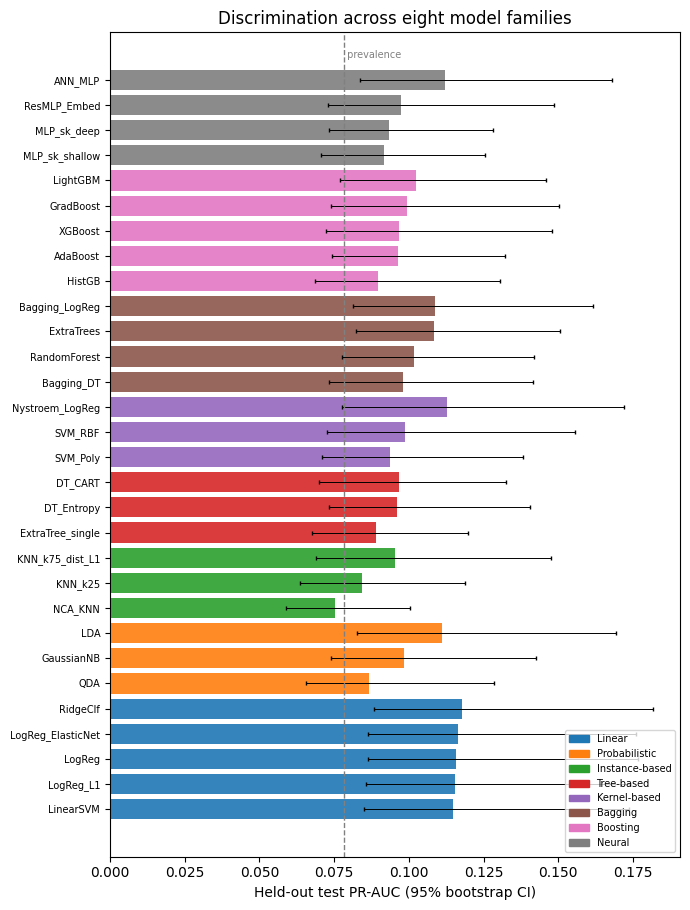

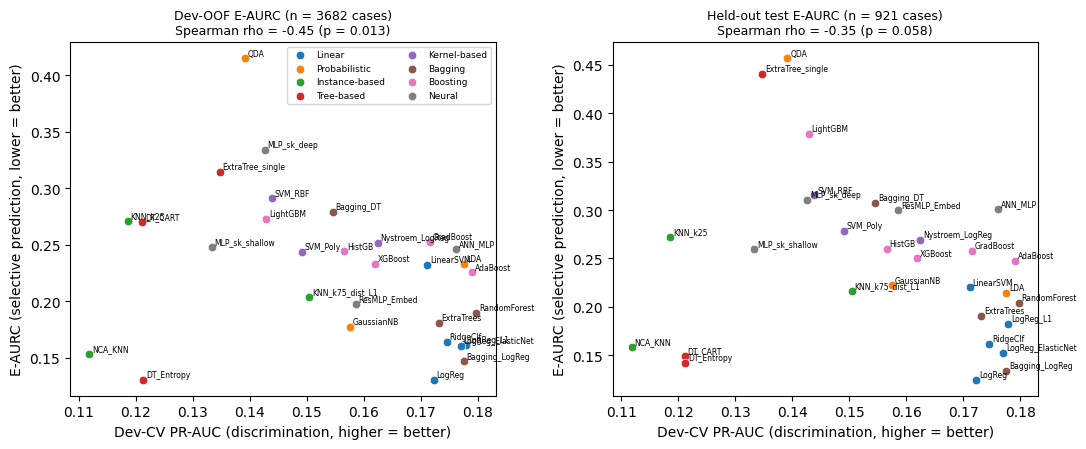

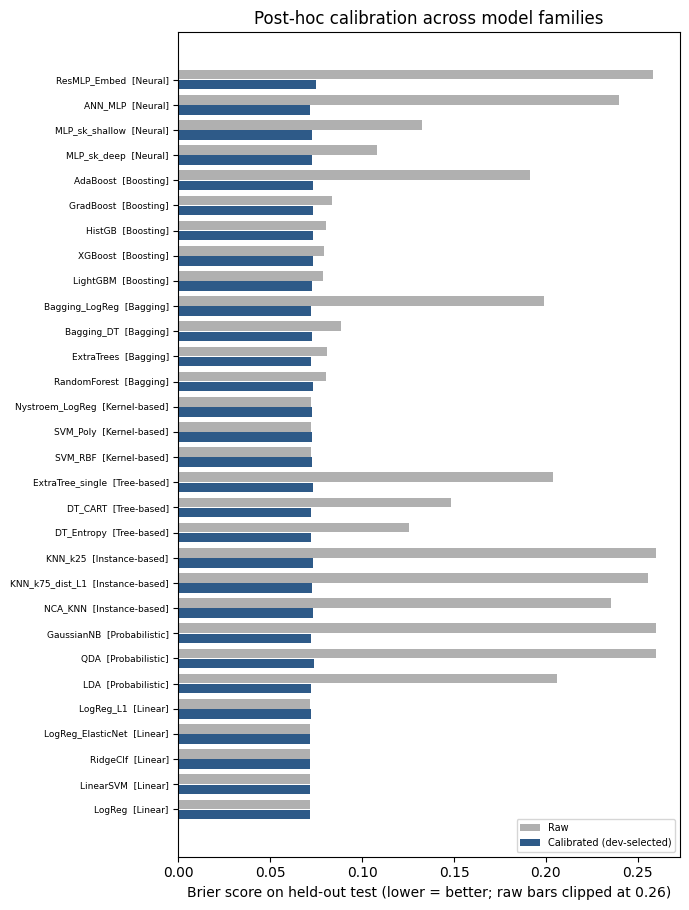

\begin{tabular}{llrrrrrrr}
\toprule
 & Family & devCV_PRAUC & test_PRAUC & test_ROCAUC & Brier_cal & ECE_cal & EAURC_dev & EAURC_test \\
Model &  &  &  &  &  &  &  &  \\
\midrule
RandomForest & Bagging & 0.180000 & 0.102000 & 0.605000 & 0.073000 & 0.026000 & 0.190000 & 0.204000 \\
Bagging_LogReg & Bagging & 0.178000 & 0.109000 & 0.616000 & 0.072000 & 0.025000 & 0.147000 & 0.134000 \\
ExtraTrees & Bagging & 0.173000 & 0.108000 & 0.622000 & 0.072000 & 0.016000 & 0.181000 & 0.191000 \\
Bagging_DT & Bagging & 0.155000 & 0.098000 & 0.577000 & 0.073000 & 0.017000 & 0.279000 & 0.308000 \\
AdaBoost & Boosting & 0.179000 & 0.096000 & 0.598000 & 0.073000 & 0.034000 & 0.226000 & 0.248000 \\
GradBoost & Boosting & 0.172000 & 0.099000 & 0.587000 & 0.073000 & 0.023000 & 0.253000 & 0.258000 \\
XGBoost & Boosting & 0.162000 & 0.097000 & 0.563000 & 0.073000 & 0.025000 & 0.233000 & 0.250000 \\
HistGB & Boosting & 0.157000 & 0.090000 & 0.557000 & 0.073000 & 0.022000 & 0.244000 & 0.260000 \\
LightGBM & Bo

In [14]:
# SECTION 4b-4: FIGURES  (saved to manuscript_figures/)
import matplotlib.pyplot as plt
os.makedirs("manuscript_figures", exist_ok=True)

FAM_ORDER = ["Linear", "Probabilistic", "Instance-based", "Tree-based",
             "Kernel-based", "Bagging", "Boosting", "Neural"]
FAM_ORDER = [f for f in FAM_ORDER if f in fam_table["Family"].unique()]
_pal = plt.cm.tab10(np.linspace(0, 1, 10))
FAM_COLOR = {f: _pal[i] for i, f in enumerate(FAM_ORDER)}

# Fig C: test PR-AUC with 95% CI, grouped by family
d = pd.concat([fam_table[fam_table["Family"] == f].sort_values("test_PRAUC") for f in FAM_ORDER])
fig, ax = plt.subplots(figsize=(7, 0.26 * len(d) + 1.4))
ypos = np.arange(len(d))
ax.barh(ypos, d["test_PRAUC"], color=[FAM_COLOR[f] for f in d["Family"]], alpha=0.9)
ax.errorbar(d["test_PRAUC"], ypos,
            xerr=[d["test_PRAUC"] - d["test_PRAUC_lo"], d["test_PRAUC_hi"] - d["test_PRAUC"]],
            fmt="none", ecolor="black", elinewidth=0.7, capsize=1.5)
ax.axvline(prev, color="grey", ls="--", lw=1)
ax.text(prev, len(d) - 0.2, " prevalence", fontsize=7, color="grey", va="bottom")
ax.set_yticks(ypos); ax.set_yticklabels(d.index, fontsize=7)
ax.set_xlabel("Held-out test PR-AUC (95% bootstrap CI)")
ax.set_title("Discrimination across eight model families")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=FAM_COLOR[f]) for f in FAM_ORDER],
          labels=FAM_ORDER, fontsize=7, loc="lower right")
fig.tight_layout(); fig.savefig("manuscript_figures/figC_family_prauc.png", dpi=600, bbox_inches="tight"); plt.show()

# Fig D: discrimination vs selective prediction (the RQ1 plot, all models)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, ycol, ttl in zip(axes, ["EAURC_dev", "EAURC_test"],
                         ["Dev-OOF E-AURC (n = %d cases)" % len(y_dev), "Held-out test E-AURC (n = %d cases)" % len(y_test)]):
    for f in FAM_ORDER:
        g = fam_table[fam_table["Family"] == f]
        ax.scatter(g["devCV_PRAUC"], g[ycol], s=38, color=FAM_COLOR[f], label=f, edgecolor="white", lw=0.5)
    for nm, r in fam_table.iterrows():
        ax.annotate(nm, (r["devCV_PRAUC"], r[ycol]), fontsize=5.5, xytext=(2, 2), textcoords="offset points")
    dd = fam_table[["devCV_PRAUC", ycol]].dropna()
    rho, pv = stats.spearmanr(dd["devCV_PRAUC"], dd[ycol])
    ax.set_title(f"{ttl}\nSpearman rho = {rho:+.2f} (p = {pv:.3f})", fontsize=9)
    ax.set_xlabel("Dev-CV PR-AUC (discrimination, higher = better)")
    ax.set_ylabel("E-AURC (selective prediction, lower = better)")
axes[0].legend(fontsize=6.5, ncol=2)
fig.tight_layout(); fig.savefig("manuscript_figures/figD_discrimination_vs_selective.png", dpi=600, bbox_inches="tight"); plt.show()

# Fig E: effect of dev-selected calibration, by family
d = pd.concat([fam_table[fam_table["Family"] == f].sort_values("Brier_raw") for f in FAM_ORDER])
fig, ax = plt.subplots(figsize=(7, 0.26 * len(d) + 1.4))
ypos = np.arange(len(d))
ax.barh(ypos + 0.2, d["Brier_raw"].clip(upper=0.26), height=0.38, color="#B0B0B0", label="Raw")
ax.barh(ypos - 0.2, d["Brier_cal"], height=0.38, color="#2E5A88", label="Calibrated (dev-selected)")
ax.set_yticks(ypos); ax.set_yticklabels([f"{n}  [{fam_table.loc[n, 'Family']}]" for n in d.index], fontsize=6.5)
ax.set_xlabel("Brier score on held-out test (lower = better; raw bars clipped at 0.26)")
ax.set_title("Post-hoc calibration across model families"); ax.legend(fontsize=7)
fig.tight_layout(); fig.savefig("manuscript_figures/figE_family_calibration.png", dpi=600, bbox_inches="tight"); plt.show()

# Table format for Latex usage
_t = fam_table.sort_values(["Family", "devCV_PRAUC"], ascending=[True, False])[
    ["Family", "devCV_PRAUC", "test_PRAUC", "test_ROCAUC", "Brier_cal", "ECE_cal", "EAURC_dev", "EAURC_test"]].round(3)
try:
    print(_t.to_latex())
except Exception as e:
    print("(to_latex needs jinja2; CSV files were saved instead)", repr(e)[:80])

In [15]:
# SECTION 4b-5: MULTI-SPLIT STABILITY ACROSS FAMILY REPRESENTATIVES
RUN_MULTI_SPLIT = False
N_SPLITS_FAMILY = 10

if RUN_MULTI_SPLIT:
    reps = fam_table.groupby("Family")["devCV_PRAUC"].idxmax()
    print("Family representatives (best dev-CV PR-AUC on the frozen split):")
    print(reps.to_string(), "\n")
    skf_ms = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    ms_rows = []
    t0 = time.time()
    for seed in range(N_SPLITS_FAMILY):
        Xd, Xt, yd, yt = train_test_split(X, y, test_size=0.2, stratify=y, random_state=1000 + seed)
        Xd = Xd.reset_index(drop=True); yd = yd.reset_index(drop=True)
        Xt = Xt.reset_index(drop=True); yt = yt.reset_index(drop=True)
        for fam, name in reps.items():
            factory = FAMILY_REGISTRY[name]["factory"]
            try:
                oof = np.zeros(len(Xd)); aps = []
                for tr, va in skf_ms.split(Xd, yd):
                    m = factory(yd.iloc[tr]); m.fit(Xd.iloc[tr], yd.iloc[tr])
                    oof[va] = m.predict_proba(Xd.iloc[va])[:, 1]
                    aps.append(average_precision_score(yd.iloc[va].values, oof[va]))
                m = factory(yd); m.fit(Xd, yd)
                p_te = m.predict_proba(Xt)[:, 1]
                best, cal_oof, _ = select_calibration_on_dev(oof, yd.values)
                cal_te = _map_fit_apply(best, oof, yd.values, p_te)
                thr = _threshold_for_sensitivity(yd.values, cal_oof)
                s = selective_metrics(yt.values, cal_te, thr, seed=seed)
                ms_rows.append({"split": seed, "Family": fam, "Model": name,
                                "devCV_PRAUC": float(np.mean(aps)),
                                "test_PRAUC": average_precision_score(yt.values, p_te),
                                "EAURC_test": s["E_AURC"], "AURC_test": s["AURC"],
                                "Brier_cal": brier_score_loss(yt.values, cal_te)})
            except Exception as e:
                print(f"split {seed} / {name} FAILED: {repr(e)[:150]}")
        print(f"split {seed + 1}/{N_SPLITS_FAMILY} done ({(time.time()-t0)/60:.1f} min)")

    ms = pd.DataFrame(ms_rows)
    ms.to_csv("family_multisplit_results.csv", index=False)
    pv_d = ms.pivot(index="split", columns="Family", values="devCV_PRAUC")
    pv_e = ms.pivot(index="split", columns="Family", values="EAURC_test")
    pv_t = ms.pivot(index="split", columns="Family", values="test_PRAUC")

    print("\nMean +/- SD across splits (family representatives):")
    print(pd.DataFrame({"devCV_PRAUC": pv_d.mean().round(4).astype(str) + " +/- " + pv_d.std().round(4).astype(str),
                        "test_PRAUC": pv_t.mean().round(4).astype(str) + " +/- " + pv_t.std().round(4).astype(str),
                        "EAURC_test": pv_e.mean().round(4).astype(str) + " +/- " + pv_e.std().round(4).astype(str)}).to_string())

    win_d = pv_d.idxmax(axis=1); win_e = pv_e.idxmin(axis=1)
    print("\nDiscrimination-best family per split:", win_d.value_counts().to_dict())
    print("Selective-best (lowest test E-AURC) family per split:", win_e.value_counts().to_dict())
    print(f"Discrimination-best family == selective-best family in {(win_d == win_e).sum()}/{len(win_d)} splits")

    rhos = [stats.spearmanr(pv_d.loc[s], pv_e.loc[s])[0] for s in pv_d.index]
    print(f"Per-split Spearman(devCV PR-AUC, test E-AURC) across families: "
          f"mean={np.nanmean(rhos):+.3f}, sd={np.nanstd(rhos, ddof=1):.3f}, range=[{np.nanmin(rhos):+.2f}, {np.nanmax(rhos):+.2f}]")
    if pv_e.shape[1] >= 3:
        for lab, pv in [("devCV PR-AUC", pv_d), ("test E-AURC", pv_e)]:
            chi, p = stats.friedmanchisquare(*[pv[c].values for c in pv.columns])
            print(f"Friedman test across families on {lab}: chi2={chi:.2f}, p={p:.4g}")
else:
    print("RUN_MULTI_SPLIT = False -> skipped (set True to run the multi-split stability check).")

RUN_MULTI_SPLIT = False -> skipped (set True to run the multi-split stability check).


## 5. CALIBRATION ANALYSIS

In [16]:
from sklearn.linear_model import LogisticRegression as _LR
from sklearn.isotonic import IsotonicRegression

BEST_BY_PRAUC = cv_comparison_table["PR_AUC_mean"].drop("Prevalence").idxmax()
print("Best model by dev CV PR-AUC:", BEST_BY_PRAUC)


def platt_calibrate(oof_p, oof_y, new_p, eps=1e-6):
    p = np.clip(oof_p, eps, 1 - eps)
    logit = np.log(p / (1 - p)).reshape(-1, 1)
    lr = _LR().fit(logit, oof_y)
    newlogit = np.log(np.clip(new_p, eps, 1 - eps) / (1 - np.clip(new_p, eps, 1 - eps))).reshape(-1, 1)
    return lr.predict_proba(newlogit)[:, 1]


def isotonic_calibrate(oof_p, oof_y, new_p):
    iso = IsotonicRegression(out_of_bounds="clip").fit(oof_p, oof_y)
    return iso.predict(new_p)


calib_compare = {}
calib_rows = []
for name in MODEL_NAMES:
    if name == "Prevalence":
        continue
    raw = test_pred[name]
    plt_ = platt_calibrate(oof_pred[name], y_dev.values, raw)
    iso_ = isotonic_calibrate(oof_pred[name], y_dev.values, raw)
    reports = {
        "raw": discrimination_calibration_report(y_test.values, raw),
        "platt": discrimination_calibration_report(y_test.values, plt_),
        "isotonic": discrimination_calibration_report(y_test.values, iso_),
    }
    calib_compare[name] = reports
    for method, rep in reports.items():
        calib_rows.append({"Model": name, "Method": method, "Brier": rep["Brier"],
                            "ECE": rep["ECE"], "Cal_slope": rep["Cal_slope"],
                            "Cal_intercept": rep["Cal_intercept"],
                            "Cal_in_the_large": rep["Cal_in_the_large"]})

calibration_table = pd.DataFrame(calib_rows).set_index(["Model", "Method"])
print("=== Calibration analysis: raw vs. Platt vs. isotonic, ALL models (held-out test set) ===")
print(calibration_table.round(4).to_string())

# Best post-hoc method per model (lowest Brier), and whether post-hoc
# calibration was actually needed (i.e. improves on raw).
best_method_rows = []
for name in MODEL_NAMES:
    if name == "Prevalence":
        continue
    briers = {m: calib_compare[name][m]["Brier"] for m in ["raw", "platt", "isotonic"]}
    best_m = min(briers, key=briers.get)
    improvement = briers["raw"] - briers[best_m]
    best_method_rows.append({"Model": name, "Best_method": best_m,
                              "Brier_raw": briers["raw"], "Brier_best": briers[best_m],
                              "Brier_improvement": improvement})
best_method_table = pd.DataFrame(best_method_rows).set_index("Model")
print("\n=== Recommended calibration method per model (by test-set Brier score) ===")
print(best_method_table.round(4))
print("\nNote: recalibration maps were fit on DEV out-of-fold predictions only and "
      "applied once to the held-out test set -- no test-set information was used "
      "to fit any calibration map (leakage-safe per the protocol).")


# Persist each model's BEST-calibrated probabilities for reuse in every
# downstream decision-support section (selective prediction, HITL, fairness,
# MoE comparator).

calibrated_test_pred = {"Prevalence": test_pred["Prevalence"]}
calibrated_oof_pred = {"Prevalence": oof_pred["Prevalence"]}
for name in MODEL_NAMES:
    if name == "Prevalence":
        continue
    best_m = best_method_table.loc[name, "Best_method"]
    if best_m == "raw":
        calibrated_test_pred[name] = test_pred[name]
        calibrated_oof_pred[name] = oof_pred[name]
    elif best_m == "platt":
        calibrated_test_pred[name] = platt_calibrate(oof_pred[name], y_dev.values, test_pred[name])
        calibrated_oof_pred[name] = platt_calibrate(oof_pred[name], y_dev.values, oof_pred[name])
    else:  # isotonic
        calibrated_test_pred[name] = isotonic_calibrate(oof_pred[name], y_dev.values, test_pred[name])
        calibrated_oof_pred[name] = isotonic_calibrate(oof_pred[name], y_dev.values, oof_pred[name])
print("\n`calibrated_test_pred` / `calibrated_oof_pred` created: every downstream "
      "decision-support section (7-10, 11) now uses each model's best-calibrated "
      "probabilities (per the table above) rather than raw pipeline output.")


def predict_calibrated(name, X):
    """Raw pipeline prediction on arbitrary X, passed through model `name`'s own
    best-fit calibration map (fit once on clean dev OOF data in this section).
    Used by Section 10 (robustness) so perturbation curves reflect what a
    deployed CALIBRATED system would actually output, not raw pipeline scores."""
    raw = fitted_models[name].predict_proba(X)[:, 1]
    best_m = best_method_table.loc[name, "Best_method"] if name != "Prevalence" else "raw"
    if best_m == "raw":
        return raw
    elif best_m == "platt":
        return platt_calibrate(oof_pred[name], y_dev.values, raw)
    else:
        return isotonic_calibrate(oof_pred[name], y_dev.values, raw)


Best model by dev CV PR-AUC: RandomForest
=== Calibration analysis: raw vs. Platt vs. isotonic, ALL models (held-out test set) ===
                        Brier     ECE  Cal_slope  Cal_intercept  Cal_in_the_large
Model        Method                                                              
LogReg       raw       0.0714  0.0187     0.7188        -0.6494            0.0011
             platt     0.0718  0.0244     0.6189        -0.8706            0.0019
             isotonic  0.0716  0.0220     0.5419        -1.0347            0.0018
LinearSVM    raw       0.0714  0.0189     0.7234        -0.6399            0.0011
             platt     0.0718  0.0212     0.6230        -0.8629            0.0019
             isotonic  0.0713  0.0210     0.5661        -0.9770            0.0019
RandomForest raw       0.0805  0.0574     0.3741        -1.6820           -0.0490
             platt     0.0732  0.0258     0.4335        -1.3196            0.0022
             isotonic  0.0734  0.0311     0.3407 

## 6. UNCERTAINTY QUANTIFICATION (UQ)

Four uncertainty families, evaluated **separately** (per the evidence review's warning against treating one family as universal):
- **Deep ensemble** — 5 independently-seeded ANNs
- **MC-dropout** — one ANN, 20 stochastic forward passes
- **Bootstrap ensemble** — 20 bootstrap-resampled calibrated logistic regressions
- **Autoencoder OOD/difficulty score** — reconstruction error in preprocessed feature space, trained on the dev set only

Each is scored by AUROC for ranking which test-set predictions are wrong.

In [17]:
from sklearn.metrics import roc_auc_score as _auc

N_SEEDS = 5
N_BOOT_MEMBERS = 20
MC_SAMPLES = 20

# A) Deep ensemble: N independently-seeded ANNs, fit on X_dev, predict X_test

t0 = time.time()
deep_ens_preds = []
for s in range(N_SEEDS):
    m = TorchMLPClassifier(cat_cols=CAT_COLS, num_cols=NUM_COLS, hidden=(64, 32),
                            p_drop=0.3, lr=1e-3, max_epochs=100, patience=8,
                            random_state=1000 + s)
    m.fit(X_dev, y_dev)
    deep_ens_preds.append(m.predict_proba(X_test)[:, 1])
deep_ens_preds = np.stack(deep_ens_preds, axis=0)
deep_ens_mean = deep_ens_preds.mean(axis=0)
deep_ens_std = deep_ens_preds.std(axis=0)
print(f"Deep ensemble ({N_SEEDS} seeds) done in {time.time()-t0:.1f}s")
print("Deep ensemble test report:", discrimination_calibration_report(y_test.values, deep_ens_mean))

# B) MC dropout on a single trained ANN

ann_model = fitted_models["ANN_MLP"]
mc_mean, mc_std = ann_model.predict_proba_mc(X_test, mc_samples=MC_SAMPLES)
print("MC-dropout test report:", discrimination_calibration_report(y_test.values, mc_mean))

# C) Bootstrap ensemble of the calibrated logistic-regression baseline

t0 = time.time()
rng = np.random.default_rng(RANDOM_STATE)
boot_preds = []
for b in range(N_BOOT_MEMBERS):
    idx = rng.integers(0, len(X_dev), len(X_dev))
    Xb, yb = X_dev.iloc[idx].reset_index(drop=True), y_dev.iloc[idx].reset_index(drop=True)
    if yb.nunique() < 2:
        continue
    m = make_logreg()
    m.fit(Xb, yb)
    boot_preds.append(m.predict_proba(X_test)[:, 1])
boot_preds = np.stack(boot_preds, axis=0)
boot_mean = boot_preds.mean(axis=0)
boot_std = boot_preds.std(axis=0)
print(f"Bootstrap ensemble ({len(boot_preds)} members) done in {time.time()-t0:.1f}s")
print("Bootstrap ensemble test report:", discrimination_calibration_report(y_test.values, boot_mean))

# D) OOD / difficulty score: autoencoder reconstruction error
pre_for_ae = build_preprocessor()
Xd_enc = pre_for_ae.fit_transform(X_dev).astype(np.float32)
Xt_enc = pre_for_ae.transform(X_test).astype(np.float32)
in_dim = Xd_enc.shape[1]


class _AE(nn.Module):
    def __init__(self, in_dim, bottleneck=8):
        super().__init__()
        self.enc = nn.Sequential(nn.Linear(in_dim, 32), nn.ReLU(), nn.Linear(32, bottleneck))
        self.dec = nn.Sequential(nn.Linear(bottleneck, 32), nn.ReLU(), nn.Linear(32, in_dim))

    def forward(self, x):
        z = self.enc(x)
        return self.dec(z)


torch.manual_seed(RANDOM_STATE)
ae = _AE(in_dim)
opt = torch.optim.Adam(ae.parameters(), lr=1e-3, weight_decay=1e-5)
Xd_t = torch.tensor(Xd_enc)
n = len(Xd_t)
for epoch in range(60):
    ae.train()
    perm = torch.randperm(n)
    for i in range(0, n, 128):
        b = perm[i:i + 128]
        opt.zero_grad()
        out = ae(Xd_t[b])
        loss = ((out - Xd_t[b]) ** 2).mean()
        loss.backward()
        opt.step()
ae.eval()
with torch.no_grad():
    recon_test = ae(torch.tensor(Xt_enc)).numpy()
ood_score = ((recon_test - Xt_enc) ** 2).mean(axis=1)
print("OOD/difficulty score (reconstruction error) range:", ood_score.min(), ood_score.max())

# E) Compare uncertainty scores: can each score rank correct vs incorrect
#    predictions?
best_test_p = test_pred[BEST_BY_PRAUC]
y_hat_best = (best_test_p >= 0.5).astype(int)
is_error_best = (y_hat_best != y_test.values).astype(int)

uncertainty_scores = {
    "DeepEnsemble_std": deep_ens_std,
    "MCDropout_std": mc_std,
    "BootstrapLR_std": boot_std,
    "Autoencoder_OOD": ood_score,
    "Confidence_dist_from_0.5 (inverted)": -np.abs(best_test_p - 0.5),
}
print("\n=== Uncertainty score: AUROC for ranking ERRORS of the best model's 0.5-threshold predictions ===")
uq_rank_rows = []
for name, score in uncertainty_scores.items():
    try:
        auc_val = _auc(is_error_best, score)
    except Exception:
        auc_val = np.nan
    uq_rank_rows.append({"Uncertainty score": name, "AUROC(error)": auc_val})
    print(f"  {name:38s} AUROC={auc_val:.3f}")
uq_rank_table = pd.DataFrame(uq_rank_rows)


Deep ensemble (5 seeds) done in 11.3s
Deep ensemble test report: {'PR_AUC': np.float64(0.11279312607603584), 'ROC_AUC': np.float64(0.6203049339091742), 'Brier': np.float64(0.21008085603994828), 'ECE': np.float64(0.3382873097667217), 'Cal_slope': 0.5040889467649641, 'Cal_intercept': -2.3450892894007644, 'Cal_in_the_large': -0.3382873303144685, 'Sensitivity': np.float64(0.5), 'Specificity': np.float64(0.6548881036513545), 'PPV': np.float64(0.1094224924012158), 'NPV': np.float64(0.9391891891891891)}
MC-dropout test report: {'PR_AUC': np.float64(0.10835104025740966), 'ROC_AUC': np.float64(0.6086899620468524), 'Brier': np.float64(0.2506288200782382), 'ECE': np.float64(0.4053361853028483), 'Cal_slope': 0.49930519726067235, 'Cal_intercept': -2.4793160172440256, 'Cal_in_the_large': -0.4051734275072328, 'Sensitivity': np.float64(0.5555555555555556), 'Specificity': np.float64(0.5736160188457008), 'PPV': np.float64(0.09950248756218906), 'NPV': np.float64(0.9383429672447013)}
Bootstrap ensemble (2

## 7. Selective prediction

In [18]:
from sklearn.metrics import precision_recall_curve as _prc

# A fixed 0.5 cut is degenerate for a ~7.9% prevalence outcome (almost no
# predicted probability ever exceeds 0.5).
_prec, _rec, _thr = _prc(y_dev.values, calibrated_oof_pred[BEST_BY_PRAUC])
_idx = np.argmin(np.abs(_rec[:-1] - 0.5))
OPERATING_THRESHOLD = float(_thr[_idx])
print(f"Operating threshold (targets ~50% sensitivity on calibrated dev OOF, {BEST_BY_PRAUC}): "
      f"{OPERATING_THRESHOLD:.4f}")


def risk_coverage(y_true, p, confidence, threshold=OPERATING_THRESHOLD):
    """Sort by descending confidence; return coverage / selective-error arrays."""
    y_true = np.asarray(y_true)
    yhat = (p >= threshold).astype(int)
    correct = (yhat == y_true).astype(int)
    order = np.argsort(-confidence)
    correct_sorted = correct[order]
    n = len(y_true)
    coverages = np.arange(1, n + 1) / n
    cum_correct = np.cumsum(correct_sorted)
    selective_error = 1 - cum_correct / np.arange(1, n + 1)
    return coverages, selective_error


def aurc(coverages, selective_error):
    return float(np.trapezoid(selective_error, coverages))


def oracle_aurc(y_true, p, threshold=OPERATING_THRESHOLD):
    """Best possible ordering: correct predictions ranked first."""
    y_true = np.asarray(y_true)
    yhat = (p >= threshold).astype(int)
    correct = (yhat == y_true).astype(int)
    order = np.argsort(-correct)  # correct cases first
    correct_sorted = correct[order]
    n = len(y_true)
    coverages = np.arange(1, n + 1) / n
    cum_correct = np.cumsum(correct_sorted)
    selective_error = 1 - cum_correct / np.arange(1, n + 1)
    return aurc(coverages, selective_error)


def high_conf_fn_rate(y_true, p, confidence, coverage=0.5, threshold=OPERATING_THRESHOLD):
    n = len(y_true)
    k = int(coverage * n)
    order = np.argsort(-confidence)[:k]
    y_sel, p_sel = np.asarray(y_true)[order], p[order]
    yhat = (p_sel >= threshold).astype(int)
    fn = ((yhat == 0) & (y_sel == 1)).sum()
    pos = (y_sel == 1).sum()
    return fn / pos if pos else np.nan


SELECTIVE_MODELS = {
    "LogReg (confidence)": (calibrated_test_pred["LogReg"],
                             np.abs(calibrated_test_pred["LogReg"] - OPERATING_THRESHOLD)),
    f"{BEST_BY_PRAUC} (confidence)": (calibrated_test_pred[BEST_BY_PRAUC],
                                       np.abs(calibrated_test_pred[BEST_BY_PRAUC] - OPERATING_THRESHOLD)),
    "ANN + MC-dropout (1/std)": (mc_mean, 1.0 / (mc_std + 1e-3)),
    "LogReg + Bootstrap-ens (1/std)": (boot_mean, 1.0 / (boot_std + 1e-3)),
}

selective_results = {}
print("=== Selective prediction summary (calibrated probabilities) ===")
for name, (p, conf) in SELECTIVE_MODELS.items():
    cov, sel_err = risk_coverage(y_test.values, p, conf)
    a = aurc(cov, sel_err)
    a_oracle = oracle_aurc(y_test.values, p)
    excess = a - a_oracle
    fn80 = high_conf_fn_rate(y_test.values, p, conf, coverage=0.8)
    selective_results[name] = dict(coverage=cov, selective_error=sel_err, AURC=a,
                                    oracle_AURC=a_oracle, excess_AURC=excess,
                                    high_conf_FN_rate_at80=fn80)
    print(f"{name:34s} AURC={a:.4f}  oracle={a_oracle:.4f}  excess={excess:.4f}  "
          f"FN-rate among top-80%-confident={fn80:.3f}")

# Which model should actually anchor the downstream decision-support sections
# (8: HITL, 9: fairness, 10: robustness)?

_confidence_candidates = {
    "LogReg": selective_results["LogReg (confidence)"]["AURC"],
    BEST_BY_PRAUC: selective_results[f"{BEST_BY_PRAUC} (confidence)"]["AURC"],
}
PRIMARY_DECISION_MODEL = min(_confidence_candidates, key=_confidence_candidates.get)
print(f"\nPrimary decision-support model for Sections 8-10 (HITL, fairness, robustness): "
      f"'{PRIMARY_DECISION_MODEL}' -- chosen by lower test-set AURC among "
      f"{_confidence_candidates}.")
if PRIMARY_DECISION_MODEL != BEST_BY_PRAUC:
    print(f"NOTE: this differs from BEST_BY_PRAUC ('{BEST_BY_PRAUC}', the dev-CV PR-AUC "
          f"winner from Section 5). That is expected and worth reporting as-is: dev-CV "
          f"discrimination rank and test-set selective-prediction quality are different "
          f"properties and need not agree, especially at this sample size. Sections 4-6 "
          f"still report the full model matrix so readers can see both.")


Operating threshold (targets ~50% sensitivity on calibrated dev OOF, RandomForest): 0.1112
=== Selective prediction summary (calibrated probabilities) ===
LogReg (confidence)                AURC=0.1802  oracle=0.0280  excess=0.1522  FN-rate among top-80%-confident=0.750
RandomForest (confidence)          AURC=0.2337  oracle=0.0332  excess=0.2005  FN-rate among top-80%-confident=0.755
ANN + MC-dropout (1/std)           AURC=0.9439  oracle=0.7226  excess=0.2214  FN-rate among top-80%-confident=0.000
LogReg + Bootstrap-ens (1/std)     AURC=0.0832  oracle=0.0364  excess=0.0468  FN-rate among top-80%-confident=0.872

Primary decision-support model for Sections 8-10 (HITL, fairness, robustness): 'LogReg' -- chosen by lower test-set AURC among {'LogReg': 0.1801933045464531, 'RandomForest': 0.2337094163951068}.
NOTE: this differs from BEST_BY_PRAUC ('RandomForest', the dev-CV PR-AUC winner from Section 5). That is expected and worth reporting as-is: dev-CV discrimination rank and test-set sele

## 7c. Stability of model selection across repeated splits


In [19]:
# STABILITY OF MODEL SELECTION ACROSS REPEATED TRAIN/TEST SPLIT

N_STABILITY_SPLITS = 15
STABILITY_MODELS = ["LogReg", "RandomForest"]
_stability_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

stability_rows = []
t0 = time.time()
for seed in range(N_STABILITY_SPLITS):
    Xd_s, Xt_s, yd_s, yt_s = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=1000 + seed)
    Xd_s = Xd_s.reset_index(drop=True); yd_s = yd_s.reset_index(drop=True)
    Xt_s = Xt_s.reset_index(drop=True); yt_s = yt_s.reset_index(drop=True)

    for model_name in STABILITY_MODELS:
        factory = make_logreg if model_name == "LogReg" else make_rf

        dev_scores = []
        for tr_idx, va_idx in _stability_cv.split(Xd_s, yd_s):
            m = factory()
            m.fit(Xd_s.iloc[tr_idx], yd_s.iloc[tr_idx])
            p_va = m.predict_proba(Xd_s.iloc[va_idx])[:, 1]
            dev_scores.append(average_precision_score(yd_s.iloc[va_idx].values, p_va))
        dev_prauc = float(np.mean(dev_scores))

        m_final = factory()
        m_final.fit(Xd_s, yd_s)
        p_test = m_final.predict_proba(Xt_s)[:, 1]
        conf_test = np.abs(p_test - 0.5)
        cov, sel_err = risk_coverage(yt_s.values, p_test, conf_test, threshold=0.5)
        test_aurc = aurc(cov, sel_err)

        stability_rows.append({"seed": seed, "model": model_name,
                                "dev_PR_AUC": dev_prauc, "test_AURC": test_aurc})
print(f"Stability check done in {time.time()-t0:.1f}s "
      f"({N_STABILITY_SPLITS} splits x {len(STABILITY_MODELS)} models x 5 folds + refit)")

stability_table = pd.DataFrame(stability_rows)
pivot_prauc = stability_table.pivot(index="seed", columns="model", values="dev_PR_AUC")
pivot_aurc = stability_table.pivot(index="seed", columns="model", values="test_AURC")

dev_winner = pivot_prauc.idxmax(axis=1)     # higher PR-AUC wins (discrimination)
test_winner = pivot_aurc.idxmin(axis=1)     # lower AURC wins (selective prediction)
agree_frac = (dev_winner == test_winner).mean()

print("\n=== Dev-CV PR-AUC vs. test-set AURC across "
      f"{N_STABILITY_SPLITS} independent random splits ===")
summary = pd.DataFrame({
    "dev_PR_AUC_mean": pivot_prauc.mean(), "dev_PR_AUC_std": pivot_prauc.std(),
    "test_AURC_mean": pivot_aurc.mean(), "test_AURC_std": pivot_aurc.std(),
})
print(summary.round(4))
print(f"\nDev-CV PR-AUC winner matches test-set AURC winner in "
      f"{agree_frac:.0%} of {N_STABILITY_SPLITS} splits "
      f"(dev-CV picks: {dev_winner.value_counts().to_dict()}; "
      f"test-AURC picks: {test_winner.value_counts().to_dict()}).")
if agree_frac < 1.0:
    print("This confirms the disagreement seen on the frozen split (Section 7) is a "
          "REPEATABLE property of this dataset at this sample size, not a one-off -- "
          "the 'best model' depends materially on which criterion and which split is "
          "used, and this instability should be reported explicitly rather than "
          "implied by a single point estimate.")
else:
    print("On this run, the dev-CV winner and test-AURC winner agreed on every split -- "
          "the disagreement seen on the frozen split (Section 7) appears to be specific "
          "to that split rather than a systematic pattern. Report both findings.")


Stability check done in 691.3s (15 splits x 2 models x 5 folds + refit)

=== Dev-CV PR-AUC vs. test-set AURC across 15 independent random splits ===
              dev_PR_AUC_mean  dev_PR_AUC_std  test_AURC_mean  test_AURC_std
model                                                                       
LogReg                 0.1644          0.0082          0.0399         0.0055
RandomForest           0.1506          0.0081          0.0388         0.0044

Dev-CV PR-AUC winner matches test-set AURC winner in 53% of 15 splits (dev-CV picks: {'LogReg': 14, 'RandomForest': 1}; test-AURC picks: {'RandomForest': 8, 'LogReg': 7}).
This confirms the disagreement seen on the frozen split (Section 7) is a REPEATABLE property of this dataset at this sample size, not a one-off -- the 'best model' depends materially on which criterion and which split is used, and this instability should be reported explicitly rather than implied by a single point estimate.


## 8. HUMAN-IN-THE-LOOP (HITL) SIMULATION

In [20]:

#
# IMPORTANT: this notebook has no access to real
# clinician review data. The "human reviewer" below is a SIMULATED decision
# source parameterised by an assumed sensitivity/specificity, used purely to
# demonstrate and evaluate the AI+human referral architecture

HITL_MODEL_NAME = PRIMARY_DECISION_MODEL
p_hitl = calibrated_test_pred[HITL_MODEL_NAME]
conf_hitl = np.abs(p_hitl - OPERATING_THRESHOLD)


HUMAN_SKILL_LEVELS = {
    "lower_bound_FRS_like": {"sensitivity": 0.79, "specificity": 0.66},
    "upper_bound_COX_like": {"sensitivity": 0.85, "specificity": 0.80},
    "midpoint": {"sensitivity": 0.82, "specificity": 0.73},
}


def simulate_human_decision(y_true, sensitivity, specificity, rng):
    y_true = np.asarray(y_true)
    out = np.zeros(len(y_true), dtype=int)
    pos_mask = y_true == 1
    neg_mask = ~pos_mask
    out[pos_mask] = rng.random(pos_mask.sum()) < sensitivity          # true positive caught w.p. sensitivity
    out[neg_mask] = rng.random(neg_mask.sum()) < (1 - specificity)    # false alarm w.p. (1 - specificity)
    return out


def system_metrics(y_true, y_pred):
    y_true = np.asarray(y_true)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    sens = tp / (tp + fn) if (tp + fn) else np.nan
    spec = tn / (tn + fp) if (tn + fp) else np.nan
    ppv = tp / (tp + fp) if (tp + fp) else np.nan
    npv = tn / (tn + fn) if (tn + fn) else np.nan
    acc = (tp + tn) / len(y_true)
    return {"sensitivity": sens, "specificity": spec, "PPV": ppv, "NPV": npv, "accuracy": acc}


def hitl_at_coverage(y_true, p, conf, coverage, human_params, threshold=OPERATING_THRESHOLD,
                      seed=RANDOM_STATE):
    """coverage = fraction of cases the AI decides automatically (highest
    confidence first); the remaining (1 - coverage) are referred to the
    simulated human."""
    n = len(y_true)
    rng = np.random.default_rng(seed)
    order = np.argsort(-conf)
    k = int(coverage * n)
    ai_idx, human_idx = order[:k], order[k:]

    y_final = np.zeros(n, dtype=int)
    y_final[ai_idx] = (p[ai_idx] >= threshold).astype(int)
    if len(human_idx) > 0:
        y_final[human_idx] = simulate_human_decision(
            np.asarray(y_true)[human_idx], human_params["sensitivity"],
            human_params["specificity"], rng)
    return system_metrics(y_true, y_final)


COVERAGE_GRID = [0.0, 0.2, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]  # 0.0 = human reviews everything

hitl_results = {}
print(f"=== HITL simulation using {HITL_MODEL_NAME} confidence for referral routing ===\n")
for skill_name, params in HUMAN_SKILL_LEVELS.items():
    rows = []
    for cov in COVERAGE_GRID:
        m = hitl_at_coverage(y_test.values, p_hitl, conf_hitl, cov, params)
        m["AI_coverage"] = cov
        rows.append(m)
    hitl_results[skill_name] = pd.DataFrame(rows).set_index("AI_coverage")
    print(f"--- Simulated reviewer: {skill_name} "
          f"(sensitivity={params['sensitivity']}, specificity={params['specificity']}) ---")
    print(hitl_results[skill_name].round(3).to_string())
    print()

# Pure-AI-alone (coverage=1.0) and pure-human-alone (coverage=0.0) are already
# the two endpoints of the grid above -- pulled out here for direct comparison.

print("=== Does AI+HITL ever beat pure human review, at a workload saving? ===")
for skill_name in HUMAN_SKILL_LEVELS:
    tab = hitl_results[skill_name]
    human_alone_sens = tab.loc[0.0, "sensitivity"]
    ai_alone_sens = tab.loc[1.0, "sensitivity"]
    hybrid = tab.drop(index=[0.0, 1.0])
    beats_human = hybrid[hybrid["sensitivity"] >= human_alone_sens]
    print(f"\n[{skill_name}] AI-alone sensitivity={ai_alone_sens:.3f} | "
          f"Human-alone sensitivity={human_alone_sens:.3f} | "
          f"Best AI+HITL sensitivity={tab['sensitivity'].max():.3f} "
          f"(at AI_coverage={tab['sensitivity'].idxmax()})")
    if len(beats_human) > 0:
        best_workload_saving = beats_human.index.max()
        print(f"  -> YES: at AI_coverage up to {best_workload_saving:.1f}, the hybrid system "
              f"matches or beats human-alone sensitivity while automating "
              f"{best_workload_saving:.0%} of cases (a genuine workload-saving result).")
    else:
        print("  -> NO: no hybrid operating point matches human-alone sensitivity here. "
              "This means referring by *distance from the operating threshold* is not "
              "identifying the cases the AI is actually reliable on for this outcome -- "
              "consistent with the same weak-confidence-signal finding from Section 7 "
              "(distance from threshold correlates only moderately with being correct, "
              "AUROC~0.6, for a rare positive class). Report this as a genuine negative "
              "result, not a success: with the current model and referral rule, full "
              "human review outperforms any AI-assisted hybrid at every workload level. "
              "A likely fix for future work is to route by a properly validated risk "
              "score / selective-classification loss rather than raw predicted-probability "
              "distance from threshold.")

print("\nReminder: the reviewer above is SIMULATED. These results demonstrate the "
      "referral architecture and its sensitivity to assumed reviewer skill; they "
      "are not a validated estimate of real clinician+AI performance.")


=== HITL simulation using LogReg confidence for referral routing ===

--- Simulated reviewer: lower_bound_FRS_like (sensitivity=0.79, specificity=0.66) ---
             sensitivity  specificity    PPV    NPV  accuracy
AI_coverage                                                  
0.0                0.847        0.643  0.168  0.980     0.659
0.2                0.806        0.698  0.185  0.977     0.707
0.4                0.681        0.754  0.190  0.965     0.748
0.5                0.625        0.777  0.192  0.961     0.765
0.6                0.542        0.792  0.181  0.953     0.772
0.7                0.486        0.799  0.170  0.948     0.774
0.8                0.389        0.821  0.156  0.941     0.787
0.9                0.319        0.824  0.134  0.935     0.785
1.0                0.264        0.816  0.109  0.929     0.773

--- Simulated reviewer: upper_bound_COX_like (sensitivity=0.85, specificity=0.8) ---
             sensitivity  specificity    PPV    NPV  accuracy
AI_coverage   

## 9. Fairness of abstention

In [21]:
FAIRNESS_MODEL_NAME = f"{PRIMARY_DECISION_MODEL} (confidence)"
p_fair = SELECTIVE_MODELS[FAIRNESS_MODEL_NAME][0]
conf_fair = SELECTIVE_MODELS[FAIRNESS_MODEL_NAME][1]
COVERAGE_BUDGET = 0.8  # accept/predict-automatically on 80% of cases; refer the rest

SUBGROUP_COLS = ["age", "Race", "gender"]


def subgroup_report(y_true, p, conf, group, col_name, coverage=0.8):
    n = len(y_true)
    k = int(coverage * n)
    order = np.argsort(-conf)
    accepted_mask = np.zeros(n, dtype=bool)
    accepted_mask[order[:k]] = True
    rows = []
    for g in sorted(pd.unique(group)):
        gm = group == g
        n_g = gm.sum()
        acc_g = gm & accepted_mask
        cov_g = acc_g.sum() / n_g if n_g else np.nan
        y_g, p_g = y_true[acc_g], p[acc_g]
        yhat_g = (p_g >= OPERATING_THRESHOLD).astype(int)
        sel_err = (yhat_g != y_g).mean() if len(y_g) else np.nan
        pos_g = (y_g == 1).sum()
        fnr = ((yhat_g == 0) & (y_g == 1)).sum() / pos_g if pos_g else np.nan
        brier_g = np.mean((p_g - y_g) ** 2) if len(y_g) else np.nan
        rows.append({"group": g, "group_label": labelled(col_name, g), "n": n_g,
                      "referred_frac": 1 - cov_g, "coverage": cov_g, "selective_error": sel_err,
                      "FNR_among_accepted": fnr, "Brier_among_accepted": brier_g})
    return pd.DataFrame(rows)


print(f"=== Unconstrained confidence referral (budget={COVERAGE_BUDGET}) using {FAIRNESS_MODEL_NAME} ===")
fairness_tables_unconstrained = {}
for col in SUBGROUP_COLS:
    tab = subgroup_report(y_test.values, p_fair, conf_fair, X_test[col].values, col, COVERAGE_BUDGET)
    fairness_tables_unconstrained[col] = tab
    print(f"\n-- by {col} --")
    display_cols = ["group", "group_label"] + [c for c in tab.columns if c not in ("group", "group_label")]
    print(tab[display_cols].round(3).to_string(index=False))


def fairness_constrained_threshold(y_true, conf, group, coverage=0.8):
    """Per-subgroup confidence threshold so every group has ~equal referral rate
    (equal coverage), rather than one global threshold that can over-refer
    a minority subgroup."""
    n = len(y_true)
    accepted_mask = np.zeros(n, dtype=bool)
    for g in sorted(pd.unique(group)):
        gm = group == g
        idx_g = np.where(gm)[0]
        k_g = int(coverage * len(idx_g))
        order_g = idx_g[np.argsort(-conf[idx_g])][:k_g]
        accepted_mask[order_g] = True
    return accepted_mask


def subgroup_report_constrained(y_true, p, conf, group, col_name, coverage=0.8):
    accepted_mask = fairness_constrained_threshold(y_true, conf, group, coverage)
    rows = []
    for g in sorted(pd.unique(group)):
        gm = group == g
        n_g = gm.sum()
        acc_g = gm & accepted_mask
        cov_g = acc_g.sum() / n_g if n_g else np.nan
        y_g, p_g = y_true[acc_g], p[acc_g]
        yhat_g = (p_g >= OPERATING_THRESHOLD).astype(int)
        sel_err = (yhat_g != y_g).mean() if len(y_g) else np.nan
        pos_g = (y_g == 1).sum()
        fnr = ((yhat_g == 0) & (y_g == 1)).sum() / pos_g if pos_g else np.nan
        rows.append({"group": g, "group_label": labelled(col_name, g), "n": n_g,
                      "referred_frac": 1 - cov_g, "coverage": cov_g, "selective_error": sel_err,
                      "FNR_among_accepted": fnr})
    return pd.DataFrame(rows)


print(f"\n=== Fairness-constrained referral (equal {COVERAGE_BUDGET} coverage per subgroup) ===")
fairness_tables_constrained = {}
for col in SUBGROUP_COLS:
    tab = subgroup_report_constrained(y_test.values, p_fair, conf_fair, X_test[col].values, col, COVERAGE_BUDGET)
    fairness_tables_constrained[col] = tab
    print(f"\n-- by {col} --")
    display_cols = ["group", "group_label"] + [c for c in tab.columns if c not in ("group", "group_label")]
    print(tab[display_cols].round(3).to_string(index=False))


=== Unconstrained confidence referral (budget=0.8) using LogReg (confidence) ===

-- by age --
 group                             group_label   n  referred_frac  coverage  selective_error  FNR_among_accepted  Brier_among_accepted
     1 Age group 1 (lowest, tentative: 18-44y) 123          0.000     1.000            0.016               1.000                 0.016
     2 Age group 2 (middle, tentative: 45-64y) 469          0.124     0.876            0.100               0.903                 0.068
     3 Age group 3 (highest, tentative: >=65y) 329          0.386     0.614            0.446               0.474                 0.088

-- by Race --
 group               group_label   n  referred_frac  coverage  selective_error  FNR_among_accepted  Brier_among_accepted
     1          Mexican American 105          0.114     0.886            0.129               0.875                 0.080
     2            Other Hispanic 101          0.139     0.861            0.103               1.000          

## 10. Robustness stress-tests

In [22]:
ROBUST_MODEL_NAME = PRIMARY_DECISION_MODEL

rng_r = np.random.default_rng(RANDOM_STATE)
NOISE_LEVELS = [0.0, 0.25, 0.5, 1.0, 1.5, 2.0]       # multiples of feature std
MISSING_RATES = [0.0, 0.05, 0.10, 0.20, 0.30]
CORRUPT_RATES = [0.0, 0.05, 0.10, 0.20, 0.30]

num_stds = X_test[NUM_COLS].std().values


def perturb_noise(X, sigma_mult, rng):
    Xp = X.copy()
    if sigma_mult > 0:
        noise = rng.normal(0, 1, size=Xp[NUM_COLS].shape) * (num_stds * sigma_mult)
        Xp[NUM_COLS] = Xp[NUM_COLS].values + noise
    return Xp


def perturb_missing(X, rate, rng):
    """Simulate missingness by imputing with fold/training median after masking
    (the fitted pipeline's own imputer handles the actual NaNs)."""
    Xp = X.copy()
    if rate > 0:
        mask = rng.random(Xp[NUM_COLS].shape) < rate
        vals = Xp[NUM_COLS].values.astype(float)
        vals[mask] = np.nan
        Xp[NUM_COLS] = vals
    return Xp


def perturb_category(X, rate, rng):
    Xp = X.copy()
    if rate > 0:
        for c in CAT_COLS:
            uniq = sorted(X[c].unique())
            flip_mask = rng.random(len(Xp)) < rate
            random_vals = rng.choice(uniq, size=flip_mask.sum())
            col = Xp[c].values.copy()
            col[flip_mask] = random_vals
            Xp[c] = col
    return Xp


def degrade(perturb_fn, levels, label):
    rows = []
    for lvl in levels:
        Xp = perturb_fn(X_test, lvl, np.random.default_rng(RANDOM_STATE + int(lvl * 100)))
        p = predict_calibrated(ROBUST_MODEL_NAME, Xp)
        rep = discrimination_calibration_report(y_test.values, p)
        # does MC-dropout uncertainty rise with corruption? (using ANN separately)
        rows.append({label: lvl, "PR_AUC": rep["PR_AUC"], "ROC_AUC": rep["ROC_AUC"],
                      "Brier": rep["Brier"], "ECE": rep["ECE"]})
    return pd.DataFrame(rows)


print(f"Robustness stress-tests for {ROBUST_MODEL_NAME} (calibrated probabilities)\n")
noise_curve = degrade(perturb_noise, NOISE_LEVELS, "noise_sigma_mult")
print("--- Gaussian noise on continuous features ---")
print(noise_curve.round(4).to_string(index=False))

missing_curve = degrade(perturb_missing, MISSING_RATES, "missing_rate")
print("\n--- Simulated missingness (imputed by pipeline's median imputer) ---")
print(missing_curve.round(4).to_string(index=False))

corrupt_curve = degrade(perturb_category, CORRUPT_RATES, "category_corrupt_rate")
print("\n--- Category corruption (random re-label of categorical fields) ---")
print(corrupt_curve.round(4).to_string(index=False))

# Does MC-dropout uncertainty rise with perturbation strength (ANN),
# ideally *before* accuracy collapses?

for lvl in NOISE_LEVELS:
    Xp = perturb_noise(X_test, lvl, np.random.default_rng(RANDOM_STATE + int(lvl * 100)))
    mean_p, std_p = ann_model.predict_proba_mc(Xp, mc_samples=MC_SAMPLES)
    rep = discrimination_calibration_report(y_test.values, mean_p)
    mc_rows.append({"noise_sigma_mult": lvl, "mean_MCdropout_std": std_p.mean(),
                      "PR_AUC": rep["PR_AUC"], "Brier": rep["Brier"]})
mc_robust = pd.DataFrame(mc_rows)
print("\n--- ANN MC-dropout uncertainty vs. noise level (does uncertainty rise before error?) ---")
print(mc_robust.round(4).to_string(index=False))


Robustness stress-tests for LogReg (calibrated probabilities)

--- Gaussian noise on continuous features ---
 noise_sigma_mult  PR_AUC  ROC_AUC  Brier    ECE
             0.00  0.1159   0.6352 0.0714 0.0187
             0.25  0.1172   0.6187 0.0719 0.0177
             0.50  0.1030   0.5928 0.0731 0.0237
             1.00  0.1019   0.5964 0.0767 0.0394
             1.50  0.1037   0.6174 0.0849 0.0607
             2.00  0.0865   0.5420 0.0970 0.0948

--- Simulated missingness (imputed by pipeline's median imputer) ---
 missing_rate  PR_AUC  ROC_AUC  Brier    ECE
         0.00  0.1159   0.6352 0.0714 0.0187
         0.05  0.1183   0.6333 0.0718 0.0170
         0.10  0.1163   0.6304 0.0716 0.0177
         0.20  0.1225   0.6161 0.0719 0.0171
         0.30  0.1300   0.6437 0.0711 0.0068

--- Category corruption (random re-label of categorical fields) ---
 category_corrupt_rate  PR_AUC  ROC_AUC  Brier    ECE
                  0.00  0.1159   0.6352 0.0714 0.0187
                  0.05  0.1195 

## 11. Mixture-of-Experts (secondary, pre-registered accept/reject rule)

Three interpretable experts — **demographic/clinical**, **cardiometabolic**, and **lifestyle/dietary** — each a logistic regression on its own feature view using the same empirically-selected imbalance strategy as the rest of the model matrix.

In [23]:
from sklearn.linear_model import LogisticRegression as _LR2

EXPERT_FEATURES = {
    "demographic_clinical": ["gender", "age", "Race", "Marital status", "Health Insurance",
                              "General health condition", "depression", "sleep disorder",
                              "sleep time"],
    "cardiometabolic": ["Systolic blood pressure", "Diastolic blood pressure",
                         "High-density lipoprotein", "Triglyceride", "Low-density lipoprotein",
                         "Fasting Glucose", "Glycohemoglobin", "Body Mass Index",
                         "Waist Circumference", "diabetes", "hypertension", "high cholesterol",
                         "Coronary Heart Disease"],
    "lifestyle_dietary": ["alcohol", "smoke", "Minutes sedentary activity", "energy", "protein",
                           "Carbohydrate", "Dietary fiber", "Total fat",
                           "Total saturated fatty acids", "Total monounsaturated fatty acids",
                           "Total polyunsaturated fatty acids", "Potassium", "Sodium"],
}
assert set(sum(EXPERT_FEATURES.values(), [])) == set(CAT_COLS + NUM_COLS)


def expert_preprocessor(feat_list):
    cat_f = [c for c in feat_list if c in CAT_COLS]
    num_f = [c for c in feat_list if c in NUM_COLS]
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_f),
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                           ("scale", StandardScaler())]), num_f),
    ], sparse_threshold=0)


def make_expert(feat_list, strategy=None):
    # Use the SAME empirically-selected imbalance strategy as the rest of the
    # model matrix (Section 3.1b), not a hardcoded default -- experts are
    # otherwise a different model family (per-domain LogReg) but should not
    # silently diverge from the pipeline's own chosen imbalance handling.
    strategy = strategy or IMBALANCE_STRATEGY
    cw = "balanced" if use_class_weight(strategy) else None
    clf = _LR2(class_weight=cw, max_iter=3000, random_state=RANDOM_STATE)
    steps = [("pre", expert_preprocessor(feat_list))]
    sampler = get_sampler(strategy)
    if sampler is not None:
        steps.append(("sampler", sampler))
    steps.append(("clf", clf))
    return ImbPipeline(steps)


class MoEClassifier(BaseEstimator, ClassifierMixin):
    """2-3 interpretable experts + a softmax gating network. Gate is trained
    only on the training fold; each expert sees only its own feature view."""

    def __init__(self, expert_features, random_state=RANDOM_STATE):
        self.expert_features = expert_features
        self.random_state = random_state

    def fit(self, X, y):
        self.expert_names_ = list(self.expert_features.keys())
        self.experts_ = {}
        expert_oof = np.zeros((len(X), len(self.expert_names_)))
        inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=self.random_state)
        # OOF predictions from each expert (fit only within inner training folds)
        # so the gate is trained on unseen-by-expert predictions -> fold-safe.
        for j, name in enumerate(self.expert_names_):
            for tr_idx, va_idx in inner_cv.split(X, y):
                m = make_expert(self.expert_features[name])
                m.fit(X.iloc[tr_idx], y.iloc[tr_idx] if hasattr(y, "iloc") else y[tr_idx])
                expert_oof[va_idx, j] = m.predict_proba(X.iloc[va_idx])[:, 1]
            # refit each expert on the FULL training fold for later inference
            m_full = make_expert(self.expert_features[name])
            m_full.fit(X, y)
            self.experts_[name] = m_full

        # Gate: small logistic-regression-based softmax router using the raw
        # full feature set to pick expert weights, trained on expert OOF preds.
        self.gate_pre_ = build_preprocessor()
        Xg = self.gate_pre_.fit_transform(X)
        self.gate_ = _LR2(max_iter=3000, random_state=self.random_state)
        # gate target = which expert was most accurate for that OOF row
        y_arr = y.values if hasattr(y, "values") else np.asarray(y)
        errs = np.abs(expert_oof - y_arr.reshape(-1, 1))
        best_expert = np.argmin(errs, axis=1)
        self.gate_.fit(Xg, best_expert)
        self.classes_ = np.array([0, 1])
        return self

    def _expert_matrix(self, X):
        P = np.zeros((len(X), len(self.expert_names_)))
        for j, name in enumerate(self.expert_names_):
            P[:, j] = self.experts_[name].predict_proba(X)[:, 1]
        return P

    def predict_proba(self, X):
        P = self._expert_matrix(X)
        Xg = self.gate_pre_.transform(X)
        weights = self.gate_.predict_proba(Xg)  # (n, n_experts)
        p1 = (P * weights).sum(axis=1)
        return np.stack([1 - p1, p1], axis=1)

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= OPERATING_THRESHOLD).astype(int)


# Fit MoE on dev, get OOF (single 5-fold, fold-safe: everything refit
# per outer fold) for a fair comparison with the single-model baselines
moe_oof = np.zeros(len(X_dev))
t0 = time.time()
for tr_idx, va_idx in OOF_CV.split(X_dev, y_dev):
    moe = MoEClassifier(EXPERT_FEATURES, random_state=RANDOM_STATE)
    moe.fit(X_dev.iloc[tr_idx], y_dev.iloc[tr_idx])
    moe_oof[va_idx] = moe.predict_proba(X_dev.iloc[va_idx])[:, 1]
print(f"MoE OOF pass done in {time.time()-t0:.1f}s")
moe_dev_report = discrimination_calibration_report(y_dev.values, moe_oof)
print("MoE dev-OOF report:", {k: round(v, 3) for k, v in moe_dev_report.items() if isinstance(v, float)})

# Final MoE fit on full dev, test-set evaluation
moe_final = MoEClassifier(EXPERT_FEATURES, random_state=RANDOM_STATE)
moe_final.fit(X_dev, y_dev)
moe_test_p = moe_final.predict_proba(X_test)[:, 1]
moe_test_report = discrimination_calibration_report(y_test.values, moe_test_p)
print("MoE TEST report:", {k: round(v, 3) for k, v in moe_test_report.items() if isinstance(v, float)})

# Simple average of the same experts (no learned gate) as an ablation
simple_avg_test_p = moe_final._expert_matrix(X_test).mean(axis=1)
simple_avg_report = discrimination_calibration_report(y_test.values, simple_avg_test_p)
print("Simple-average-of-experts TEST report:",
      {k: round(v, 3) for k, v in simple_avg_report.items() if isinstance(v, float)})

print(f"\nComparator -- single best model ({BEST_BY_PRAUC}), BEST-CALIBRATED (per Section 5) "
      f"TEST report:")
baseline_calibrated_report = discrimination_calibration_report(y_test.values, calibrated_test_pred[BEST_BY_PRAUC])
print({k: round(v, 3) for k, v in baseline_calibrated_report.items() if isinstance(v, float)})
print("(Comparing MoE against the CALIBRATED single-model baseline, not the raw pipeline output, "
      "is the harder and fairer bar -- MoE has to beat the best practical baseline, not a "
      "deliberately weakened one.)")

brier_ok = moe_test_report["Brier"] <= baseline_calibrated_report["Brier"] * 1.25  # allow modest tolerance
prauc_ok = (moe_test_report["PR_AUC"] > baseline_calibrated_report["PR_AUC"]
            and moe_test_report["PR_AUC"] > simple_avg_report["PR_AUC"])
if prauc_ok and brier_ok:
    moe_verdict = "MoE improved PR-AUC over both the calibrated single best model and simple averaging, without materially worsening calibration -- the MoE claim is supported."
else:
    reasons = []
    if not prauc_ok:
        reasons.append("no clear PR-AUC gain over the calibrated single best model / simple averaging")
    if not brier_ok:
        reasons.append(f"calibration is materially worse (Brier {moe_test_report['Brier']:.3f} vs "
                        f"{baseline_calibrated_report['Brier']:.3f} for calibrated {BEST_BY_PRAUC})")
    moe_verdict = ("Per the pre-registered protocol (reject MoE if it only helps discrimination while "
                    "losing calibration), the MoE claim is REJECTED on this dataset: " + "; ".join(reasons) + ".")
print("\nMoE verdict:", moe_verdict)


MoE OOF pass done in 7.0s
MoE dev-OOF report: {'PR_AUC': np.float64(0.157), 'ROC_AUC': np.float64(0.686), 'Brier': np.float64(0.127), 'ECE': np.float64(0.199), 'Cal_slope': 0.651, 'Cal_intercept': -1.876, 'Cal_in_the_large': -0.199, 'Sensitivity': np.float64(0.303), 'Specificity': np.float64(0.884), 'PPV': np.float64(0.183), 'NPV': np.float64(0.937)}
MoE TEST report: {'PR_AUC': np.float64(0.108), 'ROC_AUC': np.float64(0.604), 'Brier': np.float64(0.131), 'ECE': np.float64(0.193), 'Cal_slope': 0.333, 'Cal_intercept': -2.106, 'Cal_in_the_large': -0.193, 'Sensitivity': np.float64(0.194), 'Specificity': np.float64(0.878), 'PPV': np.float64(0.119), 'NPV': np.float64(0.928)}
Simple-average-of-experts TEST report: {'PR_AUC': np.float64(0.116), 'ROC_AUC': np.float64(0.641), 'Brier': np.float64(0.189), 'ECE': np.float64(0.324), 'Cal_slope': 0.718, 'Cal_intercept': -2.249, 'Cal_in_the_large': -0.324, 'Sensitivity': np.float64(0.486), 'Specificity': np.float64(0.724), 'PPV': np.float64(0.13), 'NPV

## 12. Explainability audit (descriptive, not causal)

In [24]:
import shap

SHAP_MODEL_NAME = "ExtraTrees" if "ExtraTrees" in fitted_models else BEST_BY_PRAUC
shap_pipeline = fitted_models[SHAP_MODEL_NAME]
pre_step = shap_pipeline.named_steps["pre"]
clf_step = shap_pipeline.named_steps["clf"]

X_test_enc = pre_step.transform(X_test)
if hasattr(X_test_enc, "toarray"):
    X_test_enc = X_test_enc.toarray()
feature_names = pre_step.get_feature_names_out()

explainer = shap.TreeExplainer(clf_step)
shap_values = explainer.shap_values(X_test_enc)
if isinstance(shap_values, list):
    shap_values_pos = shap_values[1]
elif shap_values.ndim == 3:
    shap_values_pos = shap_values[:, :, 1]
else:
    shap_values_pos = shap_values

mean_abs_shap = np.abs(shap_values_pos).mean(axis=0)
readable_names = [relabel_onehot_feature(f) for f in feature_names]
shap_importance = (pd.DataFrame({"feature": feature_names, "feature_readable": readable_names,
                                   "mean_abs_shap": mean_abs_shap})
                     .sort_values("mean_abs_shap", ascending=False).reset_index(drop=True))
print(f"SHAP descriptive audit for {SHAP_MODEL_NAME} (top 15 features by mean |SHAP|):")
print(shap_importance[["feature_readable", "mean_abs_shap"]].head(15).to_string(index=False))
print("\n(Raw encoded feature names retained in `shap_importance['feature']` for reproducibility; "
      "readable labels come from the category-coding resolution in Section 1b -- 'age' labels "
      "are tentative, see that section's confidence notes.)")


SHAP descriptive audit for ExtraTrees (top 15 features by mean |SHAP|):
                             feature_readable  mean_abs_shap
age = Age group 3 (highest, tentative: >=65y)       0.070756
              General health condition = Fair       0.027713
                       high cholesterol = Yes       0.021204
                 Coronary Heart Disease = Yes       0.021114
age = Age group 1 (lowest, tentative: 18-44y)       0.018894
age = Age group 2 (middle, tentative: 45-64y)       0.018796
                        high cholesterol = No       0.018392
                                  smoke = Yes       0.017599
                                   smoke = No       0.016430
                  Coronary Heart Disease = No       0.015868
             Body Mass Index = Obese (>=30.0)       0.015628
              General health condition = Good       0.013937
                            hypertension = No       0.011634
                           hypertension = Yes       0.011022
             

## 13. Reporting figures

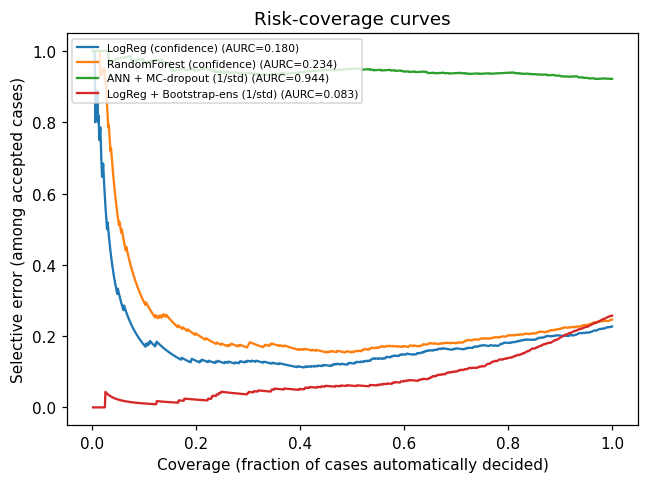

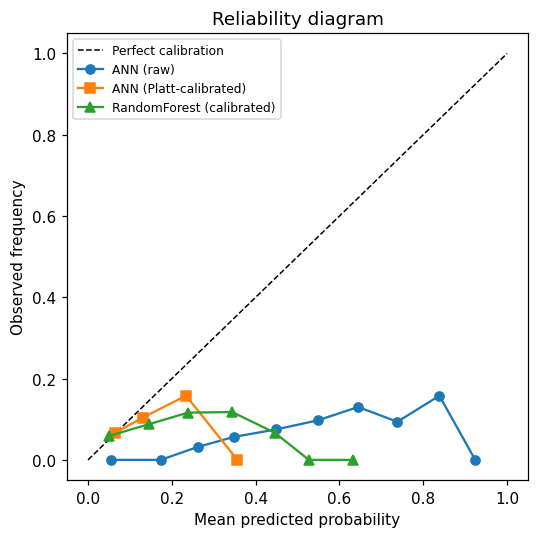

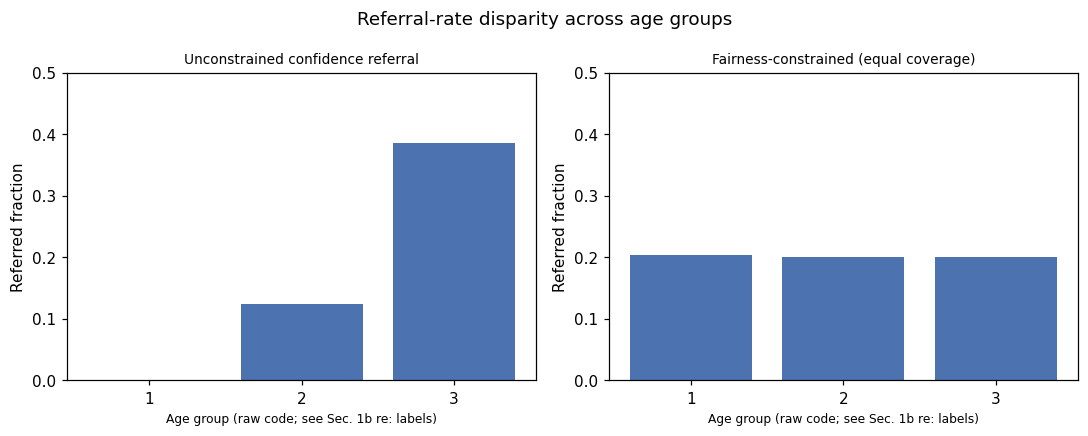

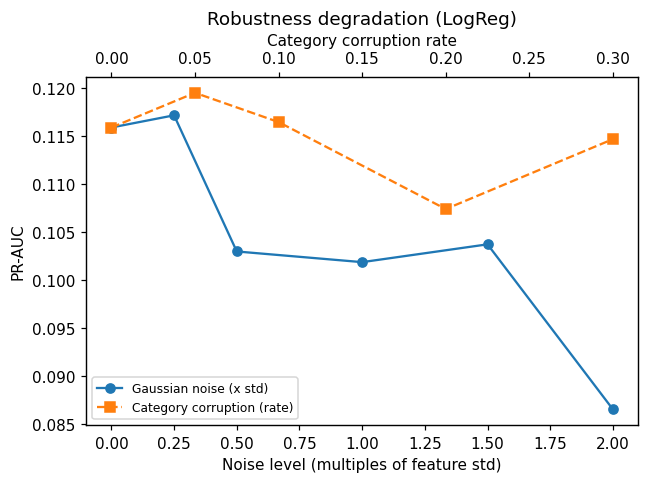

Figures saved: fig1_risk_coverage.png, fig2_reliability.png, fig3_fairness_age.png, fig4_robustness.png


In [25]:
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110

# Figure 1: risk-coverage curves
fig, ax = plt.subplots(figsize=(6, 4.5))
for name, res in selective_results.items():
    ax.plot(res["coverage"], res["selective_error"], label=f"{name} (AURC={res['AURC']:.3f})")
ax.set_xlabel("Coverage (fraction of cases automatically decided)")
ax.set_ylabel("Selective error (among accepted cases)")
ax.set_title("Risk-coverage curves")
ax.legend(fontsize=7, loc="upper left")
fig.tight_layout()
fig.savefig("fig1_risk_coverage.png")
plt.show()

# Figure 2: reliability diagram (raw vs Platt-calibrated ANN)
def reliability_points(y_true, p, n_bins=10):
    bins = np.linspace(0, 1, n_bins + 1)
    xs, ys = [], []
    for i in range(n_bins):
        lo, hi = bins[i], bins[i + 1]
        m = (p > lo) & (p <= hi) if i > 0 else (p >= lo) & (p <= hi)
        if m.sum() == 0:
            continue
        xs.append(p[m].mean()); ys.append(y_true[m].mean())
    return xs, ys

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Perfect calibration")
xs, ys = reliability_points(y_test.values, test_pred["ANN_MLP"])
ax.plot(xs, ys, "o-", label="ANN (raw)")
ann_platt = platt_calibrate(oof_pred["ANN_MLP"], y_dev.values, test_pred["ANN_MLP"])
xs, ys = reliability_points(y_test.values, ann_platt)
ax.plot(xs, ys, "s-", label="ANN (Platt-calibrated)")
xs, ys = reliability_points(y_test.values, test_pred[BEST_BY_PRAUC])
ax.plot(xs, ys, "^-", label=f"{BEST_BY_PRAUC} (calibrated)")
ax.set_xlabel("Mean predicted probability"); ax.set_ylabel("Observed frequency")
ax.set_title("Reliability diagram"); ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig("fig2_reliability.png")
plt.show()

# Figure 3: subgroup fairness (age) unconstrained vs constrained

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, tab, title in zip(axes,
                           [fairness_tables_unconstrained["age"], fairness_tables_constrained["age"]],
                           ["Unconstrained confidence referral", "Fairness-constrained (equal coverage)"]):
    ax.bar(tab["group"].astype(str), tab["referred_frac"], color="#4C72B0")
    ax.set_title(title, fontsize=9)
    ax.set_xlabel("Age group (raw code; see Sec. 1b re: labels)", fontsize=8)
    ax.set_ylabel("Referred fraction")
    ax.set_ylim(0, max(0.5, tab["referred_frac"].max() * 1.2))
fig.suptitle("Referral-rate disparity across age groups")
fig.tight_layout()
fig.savefig("fig3_fairness_age.png")
plt.show()

# Figure 4: robustness degradation curves
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(noise_curve["noise_sigma_mult"], noise_curve["PR_AUC"], "o-", label="Gaussian noise (x std)")
ax2 = ax.twiny()
ax2.plot(corrupt_curve["category_corrupt_rate"], corrupt_curve["PR_AUC"], "s--", color="tab:orange",
          label="Category corruption (rate)")
ax.set_xlabel("Noise level (multiples of feature std)")
ax2.set_xlabel("Category corruption rate")
ax.set_ylabel("PR-AUC")
ax.set_title(f"Robustness degradation ({ROBUST_MODEL_NAME})")
lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2, fontsize=8, loc="lower left")
fig.tight_layout()
fig.savefig("fig4_robustness.png")
plt.show()

print("Figures saved: fig1_risk_coverage.png, fig2_reliability.png, fig3_fairness_age.png, fig4_robustness.png")


Saved: manuscript_figures/figA_split_stability_quadrant.png (600 DPI)


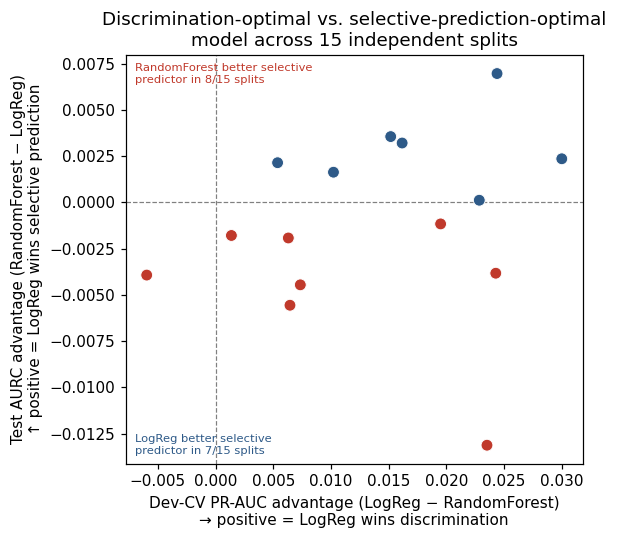

Saved: manuscript_figures/figB_hitl_coverage_curve.png (600 DPI)


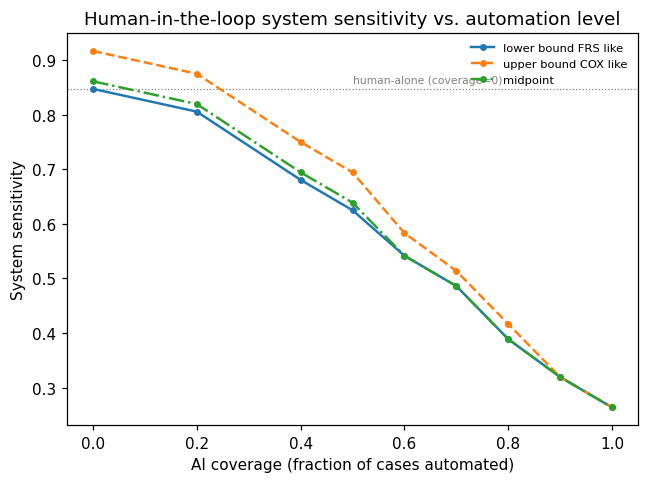

Saved: manuscript_figures/figC_model_comparison.png (600 DPI)


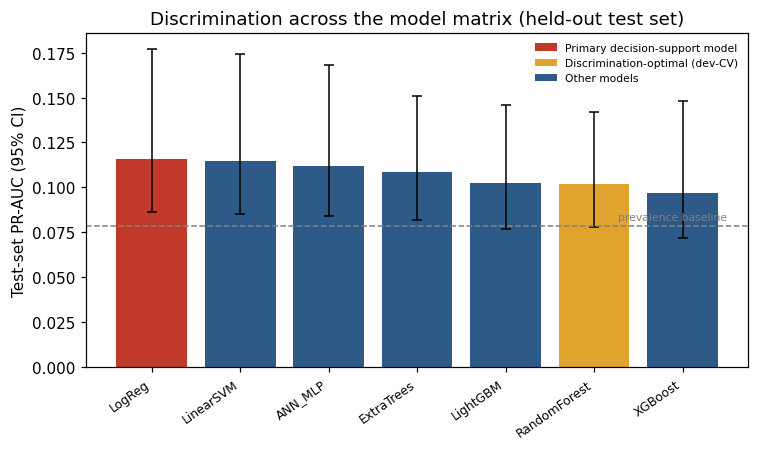

Saved: manuscript_figures/figD_calibration_summary.png (600 DPI)


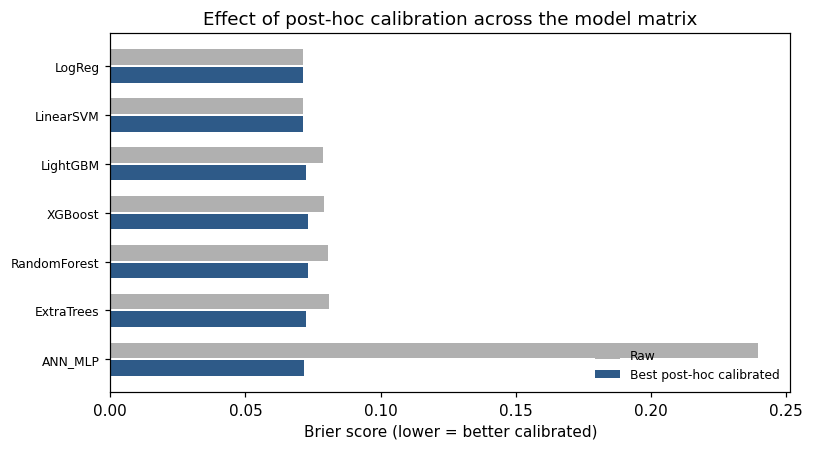

Saved: manuscript_figures/figE_shap_importance.png (600 DPI)


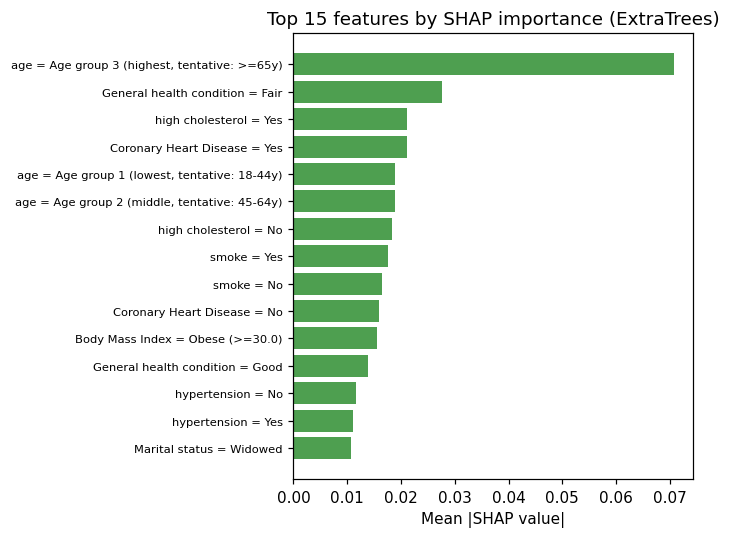


All 5 new manuscript figures saved to manuscript_figures at 600 DPI.

MANUSCRIPT NUMBERS SUMMARY
N = 4603, prevalence = 0.0786
Imbalance strategy selected: BorderlineSMOTE
Discrimination-optimal (dev-CV) model: RandomForest
Primary decision-support model: LogReg

--- Test-set PR-AUC / ROC-AUC range across matrix ---
              PR_AUC       PR_AUC_CI  ROC_AUC      ROC_AUC_CI
Model                                                        
Prevalence    0.0782  (0.063, 0.096)   0.5000      (0.5, 0.5)
LogReg        0.1159  (0.086, 0.177)   0.6352  (0.581, 0.692)
LinearSVM     0.1147  (0.085, 0.174)   0.6342  (0.578, 0.691)
RandomForest  0.1016  (0.078, 0.142)   0.6050  (0.543, 0.661)
ExtraTrees    0.1083  (0.082, 0.151)   0.6216  (0.567, 0.681)
XGBoost       0.0966  (0.072, 0.148)   0.5626  (0.503, 0.626)
LightGBM      0.1024  (0.077, 0.146)   0.5752   (0.51, 0.642)
ANN_MLP       0.1120  (0.084, 0.168)   0.6122  (0.545, 0.678)

PR-AUC range: 0.078 - 0.116
ROC-AUC range: 0.500 - 0.635

--

In [26]:
MANUSCRIPT_DIR = "manuscript_figures"
import os
os.makedirs(MANUSCRIPT_DIR, exist_ok=True)

# Local color constants (not defined in the modeling pipeline's own figures module)
STROKE_COLOR = "#C0392B"
NO_STROKE_COLOR = "#2E5A88"

def savefig2(fig, name):
    path = f"{MANUSCRIPT_DIR}/{name}.png"
    fig.savefig(path, dpi=600, bbox_inches="tight")
    print(f"Saved: {path} (600 DPI)")

# NEW FIGURE A: Split-stability quadrant plot

fig, ax = plt.subplots(figsize=(5.5, 5))
dev_diff = pivot_prauc["LogReg"] - pivot_prauc["RandomForest"]      # >0 favors LogReg
test_diff = pivot_aurc["LogReg"] - pivot_aurc["RandomForest"]        # AURC: <0 favors LogReg (lower=better)
colors = ["#2E5A88" if td < 0 else "#C0392B" for td in test_diff]
ax.axhline(0, color="grey", lw=0.8, ls="--")
ax.axvline(0, color="grey", lw=0.8, ls="--")
ax.scatter(dev_diff, -test_diff, c=colors, s=60, edgecolor="white", linewidth=0.6, zorder=3)
ax.set_xlabel("Dev-CV PR-AUC advantage (LogReg \u2212 RandomForest)\n\u2192 positive = LogReg wins discrimination")
ax.set_ylabel("Test AURC advantage (RandomForest \u2212 LogReg)\n\u2191 positive = LogReg wins selective prediction")
ax.set_title("Discrimination-optimal vs. selective-prediction-optimal\nmodel across 15 independent splits")
n_logreg_test = (test_diff < 0).sum()
n_rf_test = (test_diff > 0).sum()
ax.text(0.02, 0.02, f"LogReg better selective\npredictor in {n_logreg_test}/15 splits",
        transform=ax.transAxes, fontsize=7.5, va="bottom", color=NO_STROKE_COLOR)
ax.text(0.02, 0.98, f"RandomForest better selective\npredictor in {n_rf_test}/15 splits",
        transform=ax.transAxes, fontsize=7.5, va="top", color=STROKE_COLOR)
fig.tight_layout()
savefig2(fig, "figA_split_stability_quadrant")
plt.show()

# NEW FIGURE B: HITL coverage curve
fig, ax = plt.subplots(figsize=(6, 4.5))
linestyles = ["-", "--", "-."]
for (skill_name, tab), ls in zip(hitl_results.items(), linestyles):
    ax.plot(tab.index, tab["sensitivity"], marker="o", markersize=3.5, linestyle=ls,
             label=skill_name.replace("_", " "), linewidth=1.6)
human_alone = list(hitl_results.values())[0].loc[0.0, "sensitivity"]
ax.axhline(human_alone, color="grey", linewidth=0.8, linestyle=":", zorder=1)
ax.text(0.5, human_alone + 0.01, "human-alone (coverage=0)", fontsize=7, color="grey")
ax.set_xlabel("AI coverage (fraction of cases automated)")
ax.set_ylabel("System sensitivity")
ax.set_title("Human-in-the-loop system sensitivity vs. automation level")
ax.legend(frameon=False, fontsize=7.5, loc="upper right")
fig.tight_layout()
savefig2(fig, "figB_hitl_coverage_curve")
plt.show()

# NEW FIGURE C: Model comparison bar chart
fig, ax = plt.subplots(figsize=(7, 4.2))
names = [n for n in MODEL_NAMES if n != "Prevalence"]
pr_means = [test_table.loc[n, "PR_AUC"] for n in names]
pr_los = [test_table.loc[n, "PR_AUC_CI"][0] for n in names]
pr_his = [test_table.loc[n, "PR_AUC_CI"][1] for n in names]
err_lo = [m - lo for m, lo in zip(pr_means, pr_los)]
err_hi = [hi - m for m, hi in zip(pr_means, pr_his)]
order = np.argsort(pr_means)[::-1]
names_o = [names[i] for i in order]
pr_means_o = [pr_means[i] for i in order]
err_lo_o = [err_lo[i] for i in order]
err_hi_o = [err_hi[i] for i in order]
bar_colors = ["#C0392B" if n == PRIMARY_DECISION_MODEL else
              "#E0A32E" if n == BEST_BY_PRAUC else "#2E5A88" for n in names_o]
ax.bar(range(len(names_o)), pr_means_o, yerr=[err_lo_o, err_hi_o], capsize=3,
       color=bar_colors, error_kw={"linewidth": 1})
ax.axhline(y.mean(), color="grey", linestyle="--", linewidth=1)
ax.text(len(names_o) - 0.5, y.mean() + 0.003, "prevalence baseline", fontsize=7, ha="right", color="grey")
ax.set_xticks(range(len(names_o))); ax.set_xticklabels(names_o, rotation=35, ha="right", fontsize=8)
ax.set_ylabel("Test-set PR-AUC (95% CI)")
ax.set_title("Discrimination across the model matrix (held-out test set)")
from matplotlib.patches import Patch
legend_elems = [Patch(facecolor="#C0392B", label="Primary decision-support model"),
                Patch(facecolor="#E0A32E", label="Discrimination-optimal (dev-CV)"),
                Patch(facecolor="#2E5A88", label="Other models")]
ax.legend(handles=legend_elems, frameon=False, fontsize=7, loc="upper right")
fig.tight_layout()
savefig2(fig, "figC_model_comparison")
plt.show()

# NEW FIGURE D: Calibration improvement summary, all models
fig, ax = plt.subplots(figsize=(7.5, 4.2))
cal_names = [n for n in MODEL_NAMES if n != "Prevalence"]
raw_brier = [calib_compare[n]["raw"]["Brier"] for n in cal_names]
best_brier = [best_method_table.loc[n, "Brier_best"] for n in cal_names]
order2 = np.argsort(raw_brier)[::-1]
cal_names_o = [cal_names[i] for i in order2]
raw_o = [raw_brier[i] for i in order2]
best_o = [best_brier[i] for i in order2]
y_pos = np.arange(len(cal_names_o))
ax.barh(y_pos + 0.18, raw_o, height=0.32, color="#B0B0B0", label="Raw")
ax.barh(y_pos - 0.18, best_o, height=0.32, color="#2E5A88", label="Best post-hoc calibrated")
ax.set_yticks(y_pos); ax.set_yticklabels(cal_names_o, fontsize=8)
ax.set_xlabel("Brier score (lower = better calibrated)")
ax.set_title("Effect of post-hoc calibration across the model matrix")
ax.legend(frameon=False, fontsize=8, loc="lower right")
fig.tight_layout()
savefig2(fig, "figD_calibration_summary")
plt.show()

# NEW FIGURE E: SHAP bar chart
fig, ax = plt.subplots(figsize=(6.5, 5))
top15 = shap_importance.head(15).iloc[::-1]
ax.barh(top15["feature_readable"], top15["mean_abs_shap"], color="#4E9F50")
ax.set_xlabel("Mean |SHAP value|")
ax.set_title(f"Top 15 features by SHAP importance ({SHAP_MODEL_NAME})")
ax.tick_params(axis="y", labelsize=7.5)
fig.tight_layout()
savefig2(fig, "figE_shap_importance")
plt.show()

print("\nAll 5 new manuscript figures saved to", MANUSCRIPT_DIR, "at 600 DPI.")


print("\n" + "=" * 70)
print("MANUSCRIPT NUMBERS SUMMARY")
print("=" * 70)
print(f"N = {len(df)}, prevalence = {y.mean():.4f}")
print(f"Imbalance strategy selected: {IMBALANCE_STRATEGY}")
print(f"Discrimination-optimal (dev-CV) model: {BEST_BY_PRAUC}")
print(f"Primary decision-support model: {PRIMARY_DECISION_MODEL}")
print("\n--- Test-set PR-AUC / ROC-AUC range across matrix ---")
print(test_table[["PR_AUC", "PR_AUC_CI", "ROC_AUC", "ROC_AUC_CI"]].round(4))
print(f"\nPR-AUC range: {test_table['PR_AUC'].min():.3f} - {test_table['PR_AUC'].max():.3f}")
print(f"ROC-AUC range: {test_table['ROC_AUC'].min():.3f} - {test_table['ROC_AUC'].max():.3f}")
print("\n--- Calibration: best-calibrated baseline (for MoE comparison) ---")
print(f"{BEST_BY_PRAUC} calibrated Brier: {baseline_calibrated_report['Brier']:.4f}")
print(f"MoE Brier: {moe_test_report['Brier']:.4f}")
print("\n--- ANN raw vs Platt-calibrated ---")
print(f"ANN raw: Brier={calib_compare['ANN_MLP']['raw']['Brier']:.4f}, ECE={calib_compare['ANN_MLP']['raw']['ECE']:.4f}")
print(f"ANN platt: Brier={calib_compare['ANN_MLP']['platt']['Brier']:.4f}, ECE={calib_compare['ANN_MLP']['platt']['ECE']:.4f}")
print("\n--- Selective prediction AURC ---")
for name, res in selective_results.items():
    print(f"{name}: AURC={res['AURC']:.4f}")
print("\n--- Split stability (N=15) ---")
print(f"Dev-CV PR-AUC winner counts: {dev_winner.value_counts().to_dict()}")
print(f"Test-AURC winner counts: {test_winner.value_counts().to_dict()}")

